## Analysis extension #5 

This notebook calibrates the developmental reference on the same independent Tabula Muris adult pancreas benchmark, but now uses **only the clean model/data outputs written by AE1b**.

The encoder set is:

- clean joint seed 17;
- clean joint seed 42;
- clean development-only seed 17;
- clean development-only seed 42.

All four encoders share the same audited developmental corpus, gene vocabulary, developmental baseline, tokenizer and masking implementation. This means AE5 can use one query-tokenization implementation for all models; the only family-specific rule is which domain token a new query receives.

Adult acinar and endocrine remain lineage sanity checks. Adult ductal remains the like-for-like normal comparator for PDAC magnitude, not a prenatal ductal-endpoint identity test.

(*note that in the notebook last running AE was labeled WP, work_package*)

## 0. Adult-normal dataset: source, exact files, and analysis role

### Dataset used

This work package uses the **original Tabula Muris** young-adult **mouse atlas**, not Tabula Muris Senis.

Source:

- **Tabula Muris Consortium**, *Transcriptomic characterization of 20 organs and tissues from mouse at single cell resolution creates a Tabula Muris*, Nature (2018), DOI `10.1038/s41586-018-0590-4`.
- Public FACS/Smart-seq2 release on Figshare.
- For AE5 we use only the **pancreas FACS/Smart-seq2 raw count matrix** plus the released FACS annotations.

We do **not** use Tabula Muris Senis ageing samples, and we do **not** use the Tabula Muris 10x/droplet arm.

### Exact local files used here

```text
adult_normal/tabula_muris/
├── FACS/
│   └── Pancreas-counts.csv
├── annotations_facs.csv
└── metadata_FACS.csv
```

Important: on the current Linux filesystem the annotation file is named **`annotations_facs.csv`** with lowercase `facs`. Linux filenames are case-sensitive.

- `Pancreas-counts.csv`: raw gene × cell Smart-seq2 count matrix.
- `annotations_facs.csv`: released per-cell annotation table. It contains `cell`, `cell_ontology_class`, `mouse.id`, `mouse.sex`, `plate.barcode`, `tissue`, and related fields.
- `metadata_FACS.csv`: retained for provenance/additional metadata checks. The core AE5 biological metadata are taken directly from `annotations_facs.csv`; we do **not** reconstruct mouse or plate IDs from cell names.

### Validation already established for this release

The raw pancreas count matrix contains **1,961 cells**. The released annotation table contains **1,564 pancreas cells**, and all 1,564 annotated pancreas cells are present in the raw count matrix.

Reconstructing the released FACS QC using:

- at least 500 detected genes, and
- more than 50,000 total counts,

gives exactly the same 1,564 cells:

```text
Raw pancreas cells:                    1961
Pass reconstructed FACS QC:            1564
Released annotated pancreas:           1564
QC-pass AND annotated:                 1564
QC-pass but not annotated:                0
Annotated but fail reconstructed QC:      0
```

Therefore the **released annotated pancreas set is treated as the authoritative post-QC population**. The notebook still reconstructs the QC and asserts exact agreement as a reproducibility check.

### Adult epithelial benchmark used for AE5

From those 1,564 released pancreas cells, the exact Cell Ontology labels used are:

- `pancreatic acinar cell` → **acinar**
- `pancreatic ductal cell` → **ductal**
- `type B pancreatic cell` → **endocrine**
- `pancreatic A cell` → **endocrine**
- `pancreatic D cell` → **endocrine**
- `pancreatic PP cell` → **endocrine**

This gives:

```text
acinar        182
ductal        161
endocrine    1052
total        1395
```

The remaining endothelial, leukocyte and pancreatic stellate cells are excluded from the adult epithelial calibration.

All three AE5 lineages occur in all four Tabula Muris pancreas mice. The notebook prints and checks the mouse × lineage table before encoding.

### Interpretation

Do **not** pool the 1,395 adult epithelial cells into the primary PDAC comparison: endocrine cells dominate numerically. Instead:

- adult acinar tests recognition of mature acinar identity;
- adult endocrine tests recognition of mature endocrine identity;
- **adult ductal is the principal like-for-like adult-normal benchmark for Burdziak N1/N2 and malignant ductal states.**


In [1]:
# Core imports
import os, re, json, glob, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import scanpy as sc
import anndata as ad
from scipy import sparse
from sklearn.decomposition import PCA

import torch
from transformers import BertForMaskedLM

RANDOM_SEED = 13
rng = np.random.default_rng(RANDOM_SEED)
np.random.seed(RANDOM_SEED)


In [ ]:
# -----------------------------
# USER CONFIGURATION — audited AE1b outputs
# -----------------------------
COMMONPATH = Path("/home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/")
AUDITED_ROOT = COMMONPATH / "revision_audited_mlm"
MANIFEST_PATH = AUDITED_ROOT / "manifest.json"

if not MANIFEST_PATH.exists():
    raise FileNotFoundError(
        f"{MANIFEST_PATH}\nRun AE1b.ipynb first."
    )

with open(MANIFEST_PATH) as f:
    AUDIT_MANIFEST = json.load(f)

DEV_H5AD = Path(AUDIT_MANIFEST["dev_h5ad"])
CANCER_H5AD = Path(AUDIT_MANIFEST["cancer_h5ad"])

ALL_SEEDS = [int(s) for s in AUDIT_MANIFEST["seeds"]]
DEV_ONLY_SEEDS = ALL_SEEDS
JOINT_SEEDS = ALL_SEEDS

K_CHOSEN = 75
DEV_REFERENCE_FRACTION = 0.80

# ------------------------------------------------------------------
# Adult-normal external benchmark: ORIGINAL Tabula Muris FACS/Smart-seq2
# ------------------------------------------------------------------
TM_DIR = COMMONPATH / "adult_normal/tabula_muris"
TM_PANCREAS_COUNTS = TM_DIR / "FACS" / "Pancreas-counts.csv"
TM_FACS_ANNOT = TM_DIR / "annotations_facs.csv"
TM_FACS_META = TM_DIR / "metadata_FACS.csv"

OUTDIR = AUDITED_ROOT / "analysis" / "ae5_adult_normal_calibration"
OUTDIR.mkdir(parents=True, exist_ok=True)

print("Audited root:", AUDITED_ROOT)
print("Seeds:", ALL_SEEDS)
print("Tabula Muris directory:", TM_DIR)
print("Output directory:", OUTDIR)


Audited root: /home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm
Seeds: [17, 42]
Tabula Muris directory: /home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/adult_normal/tabula_muris
Output directory: /home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/wp5_adult_normal_calibration


In [ ]:
# -----------------------------
# Exact audited encoder directories written by AE1b
# -----------------------------
ENCODERS = {}

for seed in JOINT_SEEDS:
    ENCODERS[f"joint_seed{seed}"] = Path(
        AUDIT_MANIFEST["models"]["joint"][str(seed)]
    )

for seed in DEV_ONLY_SEEDS:
    ENCODERS[f"development_only_seed{seed}"] = Path(
        AUDIT_MANIFEST["models"]["development_only"][str(seed)]
    )

missing = {name: str(path) for name, path in ENCODERS.items() if not path.exists()}
if missing:
    raise FileNotFoundError(
        "AE5 consumes only AE1b audited checkpoints. Missing:\n"
        + json.dumps(missing, indent=2)
    )

print("Encoders used by AE5:")
for name, path in ENCODERS.items():
    print(f"  {name:28s} -> {path}")


Encoders used by WP5:
  joint_seed17                 -> /home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/models/joint/seed_17/model
  joint_seed42                 -> /home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/models/joint/seed_42/model
  development_only_seed17      -> /home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/models/development_only/seed_17/model
  development_only_seed42      -> /home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/models/development_only/seed_42/model


In [4]:
# -----------------------------
# Check local Tabula Muris files
# -----------------------------
# The annotation file on this system is `annotations_facs.csv` (lowercase facs).
# The core adult analysis uses:
#   - FACS/Pancreas-counts.csv
#   - annotations_facs.csv
# metadata_FACS.csv is also retained and loaded for provenance/additional checks.

required_tm = {
    "pancreas counts": TM_PANCREAS_COUNTS,
    "cell annotations": TM_FACS_ANNOT,
    "FACS metadata": TM_FACS_META,
}

for label, p in required_tm.items():
    print(f"{'OK  ' if p.exists() else 'MISS'} {label:18s} -> {p}")

missing_tm = {label: str(p) for label, p in required_tm.items() if not p.exists()}
if missing_tm:
    raise FileNotFoundError(
        "Required Tabula Muris files are missing.\n\n"
        "Expected under:\n"
        f"  {TM_DIR}\n\n"
        "with:\n"
        "  FACS/Pancreas-counts.csv\n"
        "  annotations_facs.csv\n"
        "  metadata_FACS.csv\n\n"
        "Missing:\n" + json.dumps(missing_tm, indent=2)
    )

for p in [DEV_H5AD, CANCER_H5AD]:
    print(("OK   " if p.exists() else "MISS "), p)


OK   pancreas counts    -> /home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/adult_normal/tabula_muris/FACS/Pancreas-counts.csv
OK   cell annotations   -> /home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/adult_normal/tabula_muris/annotations_facs.csv
OK   FACS metadata      -> /home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/adult_normal/tabula_muris/metadata_FACS.csv
OK    /home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/development/A_dev_aligned_clean.h5ad
OK    /home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/pdac/A_cancer_aligned_clean.h5ad


## 1. Load and validate the independent adult-normal pancreas

The developmental and Burdziak objects are the aligned raw-count inputs used by the existing project pipeline.

For Tabula Muris, this notebook reads the **original FACS/Smart-seq2 pancreas raw count table** and the released annotation table. The validation is deliberately performed before constructing the final adult `AnnData`:

1. restrict the released annotation table to `tissue == pancreas`;
2. verify that all released pancreas annotation cell IDs occur in `Pancreas-counts.csv`;
3. remove ERCC spike-ins from the gene matrix;
4. reconstruct the released FACS QC from the raw counts;
5. assert that the reconstructed QC-pass cells are **exactly** the 1,564 released annotated pancreas cells;
6. build the adult pancreas object from those authoritative released cells;
7. attach `mouse.id`, `mouse.sex`, `plate.barcode`, `cell_ontology_class`, etc. **directly from `annotations_facs.csv`**;
8. select the six exact released pancreatic epithelial labels used for AE5.

The 397 raw count-matrix cells absent from `annotations_facs.csv` are therefore not re-annotated or rescued: they are pre-QC cells and are excluded.


In [5]:
A_dev = sc.read_h5ad(DEV_H5AD)
A_can = sc.read_h5ad(CANCER_H5AD)

# Original Tabula Muris FACS/Smart-seq2 files.
# Pancreas-counts.csv is gene x cell.
TM_counts = pd.read_csv(TM_PANCREAS_COUNTS, index_col=0, low_memory=False)
TM_annot = pd.read_csv(TM_FACS_ANNOT, low_memory=False)
TM_meta = pd.read_csv(TM_FACS_META, low_memory=False)

print("Development:", A_dev.shape)
print("Burdziak:   ", A_can.shape)
print("TM pancreas raw table (genes x cells):", TM_counts.shape)
print("TM annotations (all tissues):", TM_annot.shape)
print("TM FACS metadata:", TM_meta.shape)

required_annot_cols = {
    "cell", "cell_ontology_class", "mouse.id", "mouse.sex",
    "plate.barcode", "tissue"
}
missing_cols = required_annot_cols - set(TM_annot.columns)
if missing_cols:
    raise KeyError(
        "annotations_facs.csv is missing required columns: "
        + ", ".join(sorted(missing_cols))
    )

print("\nRequired annotation columns present.")


Development: (34760, 15376)
Burdziak:    (28131, 15376)
TM pancreas raw table (genes x cells): (23433, 1961)
TM annotations (all tissues): (44949, 24)
TM FACS metadata: (247, 6)

Required annotation columns present.


In [ ]:
# -----------------------------
# Validate the original Tabula Muris FACS pancreas release
# and build the authoritative post-QC pancreas AnnData.
# -----------------------------

# Expected values for the specific original FACS release used in AE5.
EXPECTED_RAW_PANCREAS_CELLS = 1961
EXPECTED_RELEASED_PANCREAS_CELLS = 1564

# 1) Restrict released annotations to pancreas.
ann_pan = TM_annot[
    TM_annot["tissue"].astype(str).str.strip().str.lower().eq("pancreas")
].copy()

ann_pan["cell"] = ann_pan["cell"].astype(str)

if ann_pan["cell"].duplicated().any():
    dup = ann_pan.loc[ann_pan["cell"].duplicated(), "cell"].head().tolist()
    raise ValueError(f"Duplicate pancreas cell IDs in annotations_facs.csv: {dup}")

print("Annotated pancreas cells:", len(ann_pan))
print("\nReleased pancreas cell types:")
print(ann_pan["cell_ontology_class"].value_counts().to_string())

print("\nMice represented:")
print(ann_pan["mouse.id"].value_counts().to_string())

# 2) Compare released annotation IDs with raw pancreas count-matrix columns.
TM_counts.index = TM_counts.index.astype(str)
TM_counts.columns = TM_counts.columns.astype(str)

raw_cells = pd.Index(TM_counts.columns)
annot_cells = pd.Index(ann_pan["cell"])

raw_set = set(raw_cells)
annot_set = set(annot_cells)

print("\nRaw pancreas cells:", len(raw_set))
print("Released annotated pancreas cells:", len(annot_set))
print("Annotation/count overlap:", len(raw_set & annot_set))
print("Counts without released annotation:", len(raw_set - annot_set))
print("Released annotations without counts:", len(annot_set - raw_set))

assert len(raw_set) == EXPECTED_RAW_PANCREAS_CELLS, (
    f"Expected {EXPECTED_RAW_PANCREAS_CELLS} raw pancreas cells, "
    f"found {len(raw_set)}. Check the Tabula Muris release."
)
assert len(annot_set) == EXPECTED_RELEASED_PANCREAS_CELLS, (
    f"Expected {EXPECTED_RELEASED_PANCREAS_CELLS} released pancreas cells, "
    f"found {len(annot_set)}."
)
assert len(annot_set - raw_set) == 0, (
    "Some released pancreas annotations are absent from Pancreas-counts.csv."
)

# 3) Remove ERCC spike-ins before biological-gene QC/model mapping.
is_ercc = TM_counts.index.str.startswith("ERCC-")
print("\nERCC rows removed:", int(is_ercc.sum()))
TM_counts_no_ercc = TM_counts.loc[~is_ercc].copy()

# 4) Reconstruct the released FACS QC directly from the raw pancreas counts.
# This has already been checked interactively and exactly reproduces the
# 1,564 released annotated pancreas cells.
tm_n_counts = TM_counts_no_ercc.sum(axis=0)
tm_n_genes = (TM_counts_no_ercc > 0).sum(axis=0)

tm_qc_pass = (tm_n_genes >= 500) & (tm_n_counts > 50_000)
qc_pass_cells = set(tm_qc_pass.index[tm_qc_pass])

print("\nQC reproduction:")
print("  Raw pancreas cells:                   ", len(raw_set))
print("  Pass reconstructed FACS QC:           ", int(tm_qc_pass.sum()))
print("  Released annotated pancreas:          ", len(annot_set))
print("  QC-pass AND annotated:                ", len(qc_pass_cells & annot_set))
print("  QC-pass but not annotated:            ", len(qc_pass_cells - annot_set))
print("  Annotated but fail reconstructed QC:  ", len(annot_set - qc_pass_cells))

assert qc_pass_cells == annot_set, (
    "Reconstructed FACS QC does not exactly match the released annotated "
    "pancreas cells. Stop before encoding and inspect the source files/QC."
)

# 5) Build cells x genes AnnData using ONLY the authoritative released
# QC-passing pancreas cells, preserving raw count-matrix column order.
keep_cells = [c for c in raw_cells if c in annot_set]

X_tm = sparse.csr_matrix(TM_counts_no_ercc.loc[:, keep_cells].T.to_numpy(dtype=np.float32, copy=False))

tm_gene_symbols = TM_counts_no_ercc.index.astype(str)

A_tm = ad.AnnData(
    X=X_tm,
    obs=ann_pan.set_index("cell").loc[keep_cells].copy(),
    var=pd.DataFrame(index=tm_gene_symbols),
)

A_tm.var["symbol"] = tm_gene_symbols
A_tm.var_names_make_unique()

# Retain the QC quantities for transparency.
A_tm.obs["n_counts_tm"] = tm_n_counts.loc[keep_cells].to_numpy()
A_tm.obs["n_genes_tm"] = tm_n_genes.loc[keep_cells].to_numpy()
A_tm.obs["dataset"] = "Tabula_Muris_original_FACS_SmartSeq2"
A_tm.obs["adult_normal_source"] = "original_Tabula_Muris_FACS"

# `annotations_facs.csv` is the authoritative source of mouse/plate metadata.
# metadata_FACS.csv is deliberately NOT used to reconstruct these fields.
for c in ["mouse.id", "mouse.sex", "plate.barcode", "cell_ontology_class", "tissue"]:
    assert c in A_tm.obs.columns, f"Missing released annotation field: {c}"

print("\nFinal authoritative Tabula Muris pancreas object:", A_tm.shape)
print("Unique mice:", A_tm.obs["mouse.id"].nunique())

# Optional provenance check against metadata_FACS.csv.
# This does not determine the biological replicate labels used below.
meta_plate_candidates = [
    c for c in TM_meta.columns
    if str(c).strip().lower() in {"plate.barcode", "plate_barcode", "plate barcode", "plate"}
]
if meta_plate_candidates:
    meta_plate_col = meta_plate_candidates[0]
    meta_plates = set(TM_meta[meta_plate_col].dropna().astype(str))
    ann_plates = set(A_tm.obs["plate.barcode"].dropna().astype(str))
    print(
        f"Plate barcodes in annotations also found in metadata_FACS.csv: "
        f"{len(ann_plates & meta_plates)}/{len(ann_plates)}"
    )
else:
    print(
        "metadata_FACS.csv has no recognized plate-barcode column; "
        "no problem for AE5 because released per-cell metadata come from annotations_facs.csv."
    )

# Release the dense raw table once validation/build is complete.
# del TM_counts, TM_counts_no_ercc, X_tm


Annotated pancreas cells: 1564

Released pancreas cell types:
cell_ontology_class
type B pancreatic cell      449
pancreatic A cell           390
pancreatic acinar cell      182
pancreatic ductal cell      161
pancreatic D cell           140
pancreatic PP cell           73
endothelial cell             66
leukocyte                    54
pancreatic stellate cell     49

Mice represented:
mouse.id
3_8_M     448
3_10_M    397
3_38_F    377
3_39_F    342

Raw pancreas cells: 1961
Released annotated pancreas cells: 1564
Annotation/count overlap: 1564
Counts without released annotation: 397
Released annotations without counts: 0

ERCC rows removed: 92

QC reproduction:
  Raw pancreas cells:                    1961
  Pass reconstructed FACS QC:            1564
  Released annotated pancreas:           1564
  QC-pass AND annotated:                 1564
  QC-pass but not annotated:             0
  Annotated but fail reconstructed QC:   0

Final authoritative Tabula Muris pancreas object: (1564, 2

In [ ]:
# -----------------------------
# Select the EXACT released adult epithelial populations required for AE5
# -----------------------------

ADULT_LINEAGE_MAP = {
    "pancreatic acinar cell": "acinar",
    "pancreatic ductal cell": "ductal",
    "type B pancreatic cell": "endocrine",
    "pancreatic A cell": "endocrine",
    "pancreatic D cell": "endocrine",
    "pancreatic PP cell": "endocrine",
}

EXPECTED_ADULT_LINEAGE_COUNTS = {
    "acinar": 182,
    "ductal": 161,
    "endocrine": 1052,
}
EXPECTED_ADULT_EPITHELIAL_CELLS = 1395

A_tm.obs["adult_lineage"] = A_tm.obs["cell_ontology_class"].map(ADULT_LINEAGE_MAP)
A_adult = A_tm[A_tm.obs["adult_lineage"].notna()].copy()

print("Adult-normal epithelial cells retained for AE5:", A_adult.n_obs)
print("\nCollapsed AE5 adult lineages:")
lineage_counts = A_adult.obs["adult_lineage"].value_counts()
print(lineage_counts.to_string())

assert A_adult.n_obs == EXPECTED_ADULT_EPITHELIAL_CELLS, (
    f"Expected {EXPECTED_ADULT_EPITHELIAL_CELLS} adult epithelial cells, "
    f"found {A_adult.n_obs}."
)
for lineage, expected_n in EXPECTED_ADULT_LINEAGE_COUNTS.items():
    found_n = int(lineage_counts.get(lineage, 0))
    assert found_n == expected_n, (
        f"Expected {expected_n} {lineage} cells, found {found_n}."
    )

print("\nFine-grained released Cell Ontology classes within each AE5 lineage:")
print(pd.crosstab(
    A_adult.obs["adult_lineage"],
    A_adult.obs["cell_ontology_class"],
    margins=True
).to_string())

# Biological-replicate check: every lineage should be represented in every mouse.
mouse_lineage = pd.crosstab(
    A_adult.obs["mouse.id"],
    A_adult.obs["adult_lineage"],
    margins=True
)
print("\nMouse x AE5 lineage:")
print(mouse_lineage.to_string())

core_mouse_lineage = pd.crosstab(
    A_adult.obs["mouse.id"],
    A_adult.obs["adult_lineage"]
)
if (core_mouse_lineage == 0).any().any():
    raise ValueError(
        "At least one AE5 adult lineage is absent from at least one mouse; "
        "inspect before using mouse-level summaries."
    )

print("\nFine endocrine composition by mouse:")
endo = A_adult[A_adult.obs["adult_lineage"] == "endocrine"]
endo_mouse = pd.crosstab(
    endo.obs["mouse.id"],
    endo.obs["cell_ontology_class"],
    margins=True
)
print(endo_mouse.to_string())

# Save the validation tables used to document the external benchmark.
mouse_lineage.to_csv(OUTDIR / "ae5_tabula_muris_mouse_by_lineage.csv")
endo_mouse.to_csv(OUTDIR / "ae5_tabula_muris_endocrine_by_mouse.csv")
A_tm.obs["cell_ontology_class"].value_counts().rename("n_cells").to_csv(
    OUTDIR / "ae5_tabula_muris_pancreas_celltype_counts.csv"
)

print("\nAdult benchmark validated.")


Adult-normal epithelial cells retained for WP5: 1395

Collapsed WP5 adult lineages:
adult_lineage
endocrine    1052
acinar        182
ductal        161

Fine-grained released Cell Ontology classes within each WP5 lineage:
cell_ontology_class  pancreatic A cell  pancreatic D cell  pancreatic PP cell  pancreatic acinar cell  pancreatic ductal cell  type B pancreatic cell   All
adult_lineage                                                                                                                                              
acinar                               0                  0                   0                     182                       0                       0   182
ductal                               0                  0                   0                       0                     161                       0   161
endocrine                          390                140                  73                       0                       0                     449  105

In [8]:
# -----------------------------
# Biological-sample columns for later summaries
# -----------------------------
# Tabula Muris: use released mouse.id DIRECTLY from annotations_facs.csv.
# There are four biological mice; cells are not independent biological replicates.

ADULT_SAMPLE_COL = "mouse.id"
assert ADULT_SAMPLE_COL in A_adult.obs.columns
assert A_adult.obs[ADULT_SAMPLE_COL].notna().all()

def choose_sample_col(obs: pd.DataFrame, priorities):
    for c in priorities:
        if c in obs.columns:
            return c
    return None

CAN_SAMPLE_COL = choose_sample_col(
    A_can.obs,
    ["mouse.id", "mouse_id", "mouse", "sample", "sample_id", "animal", "batch"]
)
DEV_SAMPLE_COL = choose_sample_col(
    A_dev.obs,
    ["embryo_id", "embryo", "mouse.id", "mouse_id", "sample", "sample_id", "batch"]
)

print("Adult sample column:", ADULT_SAMPLE_COL)
print("Adult biological mice:", A_adult.obs[ADULT_SAMPLE_COL].nunique())
print("Cancer sample column:", CAN_SAMPLE_COL)
print("Dev sample column:   ", DEV_SAMPLE_COL)

print("\nAdult mouse IDs:")
print(A_adult.obs[ADULT_SAMPLE_COL].value_counts().to_string())


Adult sample column: mouse.id
Adult biological mice: 4
Cancer sample column: batch
Dev sample column:    embryo_id

Adult mouse IDs:
mouse.id
3_8_M     383
3_38_F    361
3_10_M    338
3_39_F    313


## 2. Frozen preprocessing for the encoders

Tabula Muris contributes **no fitting parameters** to the representation.

The adult cells enter each encoder using the same frozen preprocessing established by the developmental model:

1. raw Smart-seq2 counts from the released Tabula Muris pancreas matrix;
2. ERCC spike-ins removed;
3. genes mapped to the encoder vocabulary;
4. per-cell library normalization to 10,000;
5. expression divided by the **developmental per-gene non-zero median baseline**;
6. top-ranked model genes tokenized exactly as in the corresponding BERT pipeline;
7. frozen encoder inference only.

For each AE4 development-only seed, `dev_baseline.npy` is loaded directly from that seed's AE4 model directory. No adult-specific normalization baseline, PCA, batch correction, or model refitting is learned from Tabula Muris.

The adult dataset is deliberately external in both study and sequencing platform; cross-study/platform displacement is therefore something AE5 measures rather than something silently corrected away.


In [9]:
# -----------------------------
# Sparse-safe matrix utilities
# -----------------------------

def as_csr(X):
    if sparse.issparse(X):
        return X.tocsr().astype(np.float32)
    return sparse.csr_matrix(np.asarray(X, dtype=np.float32))


def library_normalize_csr(X, target_sum=1e4):
    X = as_csr(X)
    lib = np.asarray(X.sum(axis=1)).ravel().astype(np.float64)
    scale = np.zeros_like(lib, dtype=np.float64)
    nz = lib > 0
    scale[nz] = float(target_sum) / lib[nz]
    Xn = sparse.diags(scale.astype(np.float32)) @ X
    return Xn.tocsr(), lib


def nonzero_median_per_gene_sparse(X):
    Xc = as_csr(X).tocsc()
    med = np.zeros(Xc.shape[1], dtype=np.float32)
    for j in range(Xc.shape[1]):
        start, end = Xc.indptr[j], Xc.indptr[j+1]
        vals = Xc.data[start:end]
        if vals.size:
            med[j] = np.median(vals)
    return med


def strip_ens_version(x):
    return re.sub(r"\.\d+$", "", str(x))


In [10]:
# -----------------------------
# Model/vocabulary inspection
# -----------------------------

def infer_top_k(model_dir: Path, has_domain_token: bool, default=128):
    tok_path = model_dir / "X_tokens.npy"
    if tok_path.exists():
        arr = np.load(tok_path, mmap_mode="r")
        L = arr.shape[1]
        return L - (3 if has_domain_token else 2)
    return default


def load_encoder_spec(name: str, model_dir: Path):
    meta_path = model_dir / "vocab_meta.json"
    if not meta_path.exists():
        raise FileNotFoundError(meta_path)
    with open(meta_path) as f:
        meta = json.load(f)

    model = BertForMaskedLM.from_pretrained(model_dir)

    gene2id = {str(k): int(v) for k, v in meta["gene2id"].items()}
    # Sort by token ID: training vocabulary order.
    model_genes = [g for g, _ in sorted(gene2id.items(), key=lambda kv: kv[1])]

    has_dev_dom = "DEV_DOM_ID" in meta
    has_can_dom = "CANCER_DOM_ID" in meta
    has_domain = has_dev_dom or has_can_dom
    top_k = infer_top_k(model_dir, has_domain_token=has_domain, default=128)

    spec = {
        "name": name,
        "model_dir": model_dir,
        "model": model,
        "meta": meta,
        "gene2id": gene2id,
        "genes": np.asarray(model_genes, dtype=object),
        "PAD_ID": int(meta["PAD_ID"]),
        "CLS_ID": int(meta["CLS_ID"]),
        "SEP_ID": int(meta["SEP_ID"]),
        "MASK_ID": int(meta["MASK_ID"]),
        "DEV_DOM_ID": int(meta["DEV_DOM_ID"]) if has_dev_dom else None,
        "CANCER_DOM_ID": int(meta["CANCER_DOM_ID"]) if has_can_dom else None,
        "vocab_size": int(meta["vocab_size"]),
        "has_domain": has_domain,
        "top_k": int(top_k),
        "seed": meta.get("seed", None),
        "training_scope": meta.get("training_scope", "joint_or_unspecified"),
    }
    return spec

encoder_specs = {name: load_encoder_spec(name, path) for name, path in ENCODERS.items()}

for name, spec in encoder_specs.items():
    print("\n", name)
    print("  genes:", len(spec["genes"]))
    print("  top_k:", spec["top_k"])
    print("  DEV_DOM_ID:", spec["DEV_DOM_ID"])
    print("  CANCER_DOM_ID:", spec["CANCER_DOM_ID"])
    print("  hidden size:", spec["model"].config.hidden_size)
    print("  training scope:", spec["training_scope"])
    print("  seed:", spec["seed"])



 joint_seed17
  genes: 15376
  top_k: 128
  DEV_DOM_ID: 15380
  CANCER_DOM_ID: 15381
  hidden size: 256
  training scope: joint
  seed: 17

 joint_seed42
  genes: 15376
  top_k: 128
  DEV_DOM_ID: 15380
  CANCER_DOM_ID: 15381
  hidden size: 256
  training scope: joint
  seed: 42

 development_only_seed17
  genes: 15376
  top_k: 128
  DEV_DOM_ID: 15380
  CANCER_DOM_ID: 15381
  hidden size: 256
  training scope: development_only
  seed: 17

 development_only_seed42
  genes: 15376
  top_k: 128
  DEV_DOM_ID: 15380
  CANCER_DOM_ID: 15381
  hidden size: 256
  training scope: development_only
  seed: 42


In [11]:
# -----------------------------
# Align any AnnData count matrix to an encoder vocabulary
# -----------------------------

def get_symbol_series(adata: ad.AnnData):
    for col in ["symbol", "gene_symbol", "gene_symbols", "gene_name", "feature_name"]:
        if col in adata.var.columns:
            return pd.Series(adata.var[col].astype(str).values, index=adata.var_names)
    return pd.Series(adata.var_names.astype(str), index=adata.var_names)


def build_model_symbol_map(spec, A_dev_reference):
    """Map uppercase mouse gene symbols -> model Ensembl/token gene IDs using A_dev_aligned.var."""
    dev_symbols = get_symbol_series(A_dev_reference)
    ens_to_symbol = {}
    for ens, sym in zip(A_dev_reference.var_names.astype(str), dev_symbols.astype(str)):
        ens_to_symbol[strip_ens_version(ens)] = sym

    symbol_to_model = {}
    duplicates = {}
    for mg in spec["genes"]:
        mg0 = strip_ens_version(mg)
        sym = ens_to_symbol.get(mg0)
        if sym is None:
            continue
        key = sym.upper()
        if key in symbol_to_model and symbol_to_model[key] != mg:
            duplicates.setdefault(key, set()).update([symbol_to_model[key], mg])
        else:
            symbol_to_model[key] = mg
    if duplicates:
        print(f"[WARN] {len(duplicates)} duplicated symbol mappings in model vocabulary; first mapping retained.")
    return symbol_to_model


def align_counts_to_model(adata: ad.AnnData, spec, A_dev_reference=None):
    """
    Return CSR counts with columns exactly in spec['genes'] order.
    Direct Ensembl matches are used first; gene-symbol mapping is used for remaining genes.
    Duplicate source genes mapping to the same model gene are summed.
    """
    model_genes = list(map(str, spec["genes"]))
    model_index = {strip_ens_version(g): j for j, g in enumerate(model_genes)}

    source_names = list(map(str, adata.var_names))
    source_symbols = get_symbol_series(adata).astype(str).values

    symbol_to_model = build_model_symbol_map(spec, A_dev_reference) if A_dev_reference is not None else {}
    exact_model = {strip_ens_version(g): g for g in model_genes}

    src_idx = []
    dst_idx = []
    direct = 0
    by_symbol = 0

    for i, (g, sym) in enumerate(zip(source_names, source_symbols)):
        g0 = strip_ens_version(g)
        mg = None
        if g0 in exact_model:
            mg = exact_model[g0]
            direct += 1
        else:
            mg = symbol_to_model.get(str(sym).upper())
            if mg is None:
                # var_names may themselves be symbols
                mg = symbol_to_model.get(str(g).upper())
            if mg is not None:
                by_symbol += 1
        if mg is not None:
            src_idx.append(i)
            dst_idx.append(model_index[strip_ens_version(mg)])

    if len(src_idx) == 0:
        raise ValueError("No genes could be mapped to model vocabulary.")

    X = as_csr(adata.X)
    # Mapping matrix: source_genes x model_genes. Multiplication sums duplicates naturally.
    M = sparse.coo_matrix(
        (np.ones(len(src_idx), dtype=np.float32), (src_idx, dst_idx)),
        shape=(adata.n_vars, len(model_genes)),
    ).tocsr()
    Xmap = (X @ M).tocsr()

    mapped_model_genes = len(set(dst_idx))
    print(
        f"Mapped {len(src_idx):,}/{adata.n_vars:,} source features onto "
        f"{mapped_model_genes:,}/{len(model_genes):,} model genes "
        f"(direct={direct:,}, symbol={by_symbol:,})."
    )
    return Xmap


In [ ]:
# ============================================================
# AUDITED DEVELOPMENTAL BASELINE
# ============================================================
#
# AE1b saves the exact developmental baseline used by every clean encoder.
# No historical baseline reconstruction is needed anymore.

def load_audited_baseline(spec):
    path = Path(spec["model_dir"]) / "dev_baseline.npy"
    if not path.exists():
        raise FileNotFoundError(path)
    b = np.load(path).astype(np.float32)
    if b.shape[0] != len(spec["genes"]):
        raise ValueError(f"{spec['name']}: baseline length does not match vocabulary.")
    spec["dev_baseline_source"] = str(path)
    return b

for name, spec in encoder_specs.items():
    spec["dev_baseline"] = load_audited_baseline(spec)
    spec["baseline_zero"] = spec["dev_baseline"] <= 0
    print(
        f"{name}: baseline={spec['dev_baseline_source']}; "
        f"zero-baseline genes={int(spec['baseline_zero'].sum()):,}"
    )

# Strong pairwise check: all audited encoders must use the same baseline.
baseline_names = list(encoder_specs)
b0 = encoder_specs[baseline_names[0]]["dev_baseline"]
for name in baseline_names[1:]:
    if not np.array_equal(b0, encoder_specs[name]["dev_baseline"]):
        raise RuntimeError(f"Audited baseline differs for encoder {name}.")
print("PASS: all audited encoders share the exact developmental baseline.")


joint_seed17: baseline=/home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/models/joint/seed_17/model/dev_baseline.npy; zero-baseline genes=78
joint_seed42: baseline=/home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/models/joint/seed_42/model/dev_baseline.npy; zero-baseline genes=78
development_only_seed17: baseline=/home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/models/development_only/seed_17/model/dev_baseline.npy; zero-baseline genes=78
development_only_seed42: baseline=/home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/models/development_only/seed_42/model/dev_baseline.npy; zero-baseline genes=78
PASS: all audited encoders share the exact developmental baseline.


## 3. Historical-corpus validation before adult encoding

Historical development and Burdziak matrices are already aligned to the model vocabulary, so validation starts directly from `A_dev_aligned.X` and `A_cancer_aligned.X`. Gene mapping is used only for the genuinely new Tabula Muris query.

The acceptance rule is encoder-specific:

- **AE4 development-only seeds 17 and 42:** DEV and Burdziak must reproduce **exactly**.
- **Original joint encoder:** DEV must reproduce **exactly**. For Burdziak, exact equality is preferred; however, a mismatch is accepted only when every discrepant cell contains the **same top-128 gene set**, differs only by an **adjacent two-token swap**, and the resulting CLS perturbation is negligible by the prespecified diagnostic tolerances used here (`min cosine >= 0.9999`, `max relative L2 <= 0.02`).

This exception is justified because the original ranking code used `np.argpartition`, whose ordering of equal-valued elements is not guaranteed. The saved historical tokens remain authoritative for all historical cancer embeddings; the tolerance is used only to validate the tokenizer for new external queries.


In [ ]:
# ============================================================
# ONE AUDITED QUERY TOKENIZER FOR ALL CLEAN ENCODERS
# ============================================================
#
# AE1b intentionally removed the old joint-vs-AE4 preprocessing discrepancy.
# All four clean encoders share this exact tokenizer.

def audited_cell_to_tokens_from_raw_row(X_row, spec, target_sum=1e4):
    if sparse.issparse(X_row):
        raw = X_row.toarray().ravel().astype(np.float32)
    else:
        raw = np.asarray(X_row).ravel().astype(np.float32)

    lib = float(raw.sum())
    top_k = int(spec["top_k"])

    if lib <= 0:
        return np.asarray(
            [spec["CLS_ID"], spec["SEP_ID"]] + [spec["PAD_ID"]] * top_k,
            dtype=np.int64,
        )

    normed = raw / lib * float(target_sum)

    safe = spec["dev_baseline"].copy()
    z = safe <= 0
    safe[z] = 1.0

    rel = normed / safe
    rel[z] = 0.0

    scores = np.log1p(np.maximum(rel, 0.0) + 1e-6)
    scores = np.nan_to_num(scores, nan=0.0, posinf=0.0, neginf=0.0)

    if np.all(scores == 0):
        return np.asarray(
            [spec["CLS_ID"], spec["SEP_ID"]] + [spec["PAD_ID"]] * top_k,
            dtype=np.int64,
        )

    k = min(top_k, scores.size)
    idx_k = np.argpartition(-scores, k - 1)[:k]
    idx_sorted = idx_k[np.argsort(-scores[idx_k], kind="stable")]

    token_ids = (
        [spec["CLS_ID"]]
        + (idx_sorted[:top_k] + 4).tolist()
        + [spec["SEP_ID"]]
    )

    if len(token_ids) < top_k + 2:
        token_ids += [spec["PAD_ID"]] * (top_k + 2 - len(token_ids))

    return np.asarray(token_ids, dtype=np.int64)


def base_tokens_from_raw_matrix(X, spec):
    n = X.shape[0]
    L = int(spec["top_k"]) + 2
    out = np.full((n, L), spec["PAD_ID"], dtype=np.int64)
    for i in range(n):
        out[i] = audited_cell_to_tokens_from_raw_row(X[i], spec)
    return out


def add_domain_token(tokens, spec, domain):
    if domain == "DEV":
        dom_id = spec["DEV_DOM_ID"]
    elif domain == "CANCER":
        dom_id = spec["CANCER_DOM_ID"]
    else:
        raise ValueError("domain must be DEV or CANCER")

    N, L = tokens.shape
    out = np.full((N, L + 1), spec["PAD_ID"], dtype=np.int64)
    out[:, 0] = dom_id
    out[:, 1:] = tokens
    attn = (out != spec["PAD_ID"]).astype(np.int64)
    return out, attn, 1


def tokenize_new_query(X_counts_aligned, spec, domain):
    base = base_tokens_from_raw_matrix(X_counts_aligned, spec)
    return add_domain_token(base, spec, domain)


def load_saved_dev_cancer_corpus(spec):
    model_dir = Path(spec["model_dir"])
    tok = np.load(model_dir / "X_tokens.npy")
    attn = np.load(model_dir / "X_attn.npy")
    dom = np.load(model_dir / "domain.npy")

    dev_mask = dom == 0
    can_mask = dom == 1

    if int(dev_mask.sum()) != A_dev.n_obs:
        raise ValueError(f"{spec['name']}: saved DEV count mismatch.")
    if int(can_mask.sum()) != A_can.n_obs:
        raise ValueError(f"{spec['name']}: saved cancer count mismatch.")

    dev_names = np.load(model_dir / "dev_obs_names.npy", allow_pickle=True).astype(str)
    can_names = np.load(model_dir / "cancer_obs_names.npy", allow_pickle=True).astype(str)

    if not np.array_equal(dev_names, A_dev.obs_names.astype(str).to_numpy()):
        raise ValueError(f"{spec['name']}: DEV cell order mismatch.")
    if not np.array_equal(can_names, A_can.obs_names.astype(str).to_numpy()):
        raise ValueError(f"{spec['name']}: cancer cell order mismatch.")

    return {
        "dev_tokens": tok[dev_mask],
        "dev_attn": attn[dev_mask],
        "cancer_tokens": tok[can_mask],
        "cancer_attn": attn[can_mask],
    }


@torch.no_grad()
def cls_embeddings(model, tokens, attn, cls_position=1, batch_size=32):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model = model.to(device)
    model.eval()

    chunks = []
    for start in range(0, tokens.shape[0], batch_size):
        x = torch.as_tensor(tokens[start:start+batch_size], dtype=torch.long, device=device)
        a = torch.as_tensor(attn[start:start+batch_size], dtype=torch.long, device=device)
        result = model.bert(input_ids=x, attention_mask=a, return_dict=True)
        chunks.append(result.last_hidden_state[:, cls_position, :].cpu())

    return torch.cat(chunks, dim=0).numpy()


In [ ]:
# ============================================================
# AUDITED TOKEN-REPRODUCTION GATE
# ============================================================
# All four encoders were produced by AE1b and therefore must reproduce
# exactly under one common tokenizer.

N_VALIDATE_PER_DOMAIN = 512

def spread_indices(n, k):
    k = min(int(k), int(n))
    if k <= 0:
        return np.array([], dtype=int)
    return np.unique(np.linspace(0, n - 1, num=k, dtype=int))

validation_rows = []

for enc_name, spec in encoder_specs.items():
    print("\n" + "=" * 70)
    print("TOKEN REPRODUCTION:", enc_name)
    print("=" * 70)

    genes = np.asarray(spec["genes"], dtype=str)
    if not np.array_equal(A_dev.var_names.astype(str).to_numpy(), genes):
        raise ValueError(f"{enc_name}: A_dev gene order differs from model vocabulary.")
    if not np.array_equal(A_can.var_names.astype(str).to_numpy(), genes):
        raise ValueError(f"{enc_name}: A_can gene order differs from model vocabulary.")

    saved = load_saved_dev_cancer_corpus(spec)
    idev = spread_indices(A_dev.n_obs, N_VALIDATE_PER_DOMAIN)
    ican = spread_indices(A_can.n_obs, N_VALIDATE_PER_DOMAIN)

    dev_base = base_tokens_from_raw_matrix(A_dev[idev].X, spec)
    can_base = base_tokens_from_raw_matrix(A_can[ican].X, spec)

    dev_re, _, _ = add_domain_token(dev_base, spec, "DEV")
    can_domain = (
        "CANCER"
        if spec["training_scope"] == "joint"
        else "DEV"
    )
    can_re, _, _ = add_domain_token(can_base, spec, can_domain)

    dev_hist = saved["dev_tokens"][idev]
    can_hist = saved["cancer_tokens"][ican]

    dev_exact = float(np.mean(np.all(dev_re == dev_hist, axis=1)))
    can_exact = float(np.mean(np.all(can_re == can_hist, axis=1)))

    validation_rows.append({
        "encoder": enc_name,
        "training_scope": spec["training_scope"],
        "seed": spec.get("seed", np.nan),
        "n_dev_checked": len(idev),
        "n_cancer_checked": len(ican),
        "dev_exact_row_match": dev_exact,
        "cancer_exact_row_match": can_exact,
        "accepted_for_adult_query": bool(dev_exact == 1.0 and can_exact == 1.0),
        "cancer_query_domain": can_domain,
        "baseline_source": spec["dev_baseline_source"],
    })

validation_df = pd.DataFrame(validation_rows)
validation_df.to_csv(OUTDIR / "ae5_audited_token_validation.csv", index=False)
display(validation_df)

if not validation_df["accepted_for_adult_query"].all():
    raise RuntimeError(
        "At least one audited encoder failed exact token reproduction. "
        "Stop before adult-normal encoding."
    )

print("PASS: all audited encoders reproduce their saved DEV/Burdziak tokens exactly.")



TOKEN REPRODUCTION: joint_seed17

TOKEN REPRODUCTION: joint_seed42

TOKEN REPRODUCTION: development_only_seed17

TOKEN REPRODUCTION: development_only_seed42


,encoder,training_scope,seed,n_dev_checked,n_cancer_checked,dev_exact_row_match,cancer_exact_row_match,accepted_for_adult_query,cancer_query_domain,baseline_source
0,joint_seed17,joint,17,512,512,1.0,1.0,True,CANCER,/home/jfpoyatos/Work/MNCN_24_25/Development_an...
1,joint_seed42,joint,42,512,512,1.0,1.0,True,CANCER,/home/jfpoyatos/Work/MNCN_24_25/Development_an...
2,development_only_seed17,development_only,17,512,512,1.0,1.0,True,DEV,/home/jfpoyatos/Work/MNCN_24_25/Development_an...
3,development_only_seed42,development_only,42,512,512,1.0,1.0,True,DEV,/home/jfpoyatos/Work/MNCN_24_25/Development_an...


PASS: all audited encoders reproduce their saved DEV/Burdziak tokens exactly.


In [15]:
# -----------------------------
# Embed exact saved dev/cancer corpora and new adult-normal queries
# This cell runs only AFTER exact historical-token reproduction has passed.
# -----------------------------

encoded = {}

for enc_name, spec in encoder_specs.items():
    print("\n==============================")
    print("ENCODER:", enc_name)
    print("==============================")

    # Development + Burdziak: use the exact token matrices saved by the
    # notebook that created this encoder.
    saved = load_saved_dev_cancer_corpus(spec)

    cls_pos = 1 if spec["has_domain"] else 0

    Xdev_emb = cls_embeddings(
        spec["model"],
        saved["dev_tokens"],
        saved["dev_attn"],
        cls_position=cls_pos,
        batch_size=32,
    )
    Xcan_emb = cls_embeddings(
        spec["model"],
        saved["cancer_tokens"],
        saved["cancer_attn"],
        cls_position=cls_pos,
        batch_size=32,
    )

    # Adult normal is the only genuinely new query corpus.
# Unlike historical DEV/Burdziak, Tabula Muris DOES require gene mapping.
    Xadult_counts = align_counts_to_model(
        A_adult, spec, A_dev_reference=A_dev
    )

    adult_embeddings = {}
    adult_tokens = {}

    if (
        spec["training_scope"] == "joint"
        and spec["DEV_DOM_ID"] is not None
        and spec["CANCER_DOM_ID"] is not None
    ):
        adult_domains = ["DEV", "CANCER"]
    else:
        adult_domains = ["DEV"] if spec["has_domain"] else [None]

    for adult_domain in adult_domains:
        tok, attn, adult_cls_pos = tokenize_new_query(
            Xadult_counts,
            spec,
            adult_domain,
        )
        emb = cls_embeddings(
            spec["model"],
            tok,
            attn,
            cls_position=adult_cls_pos,
            batch_size=32,
        )
        key = adult_domain or "NONE"
        adult_embeddings[key] = emb
        adult_tokens[key] = (tok, attn)

    encoded[enc_name] = {
        "dev": Xdev_emb,
        "cancer": Xcan_emb,
        "adult": adult_embeddings,
        "dev_tokens": saved["dev_tokens"],
        "cancer_tokens": saved["cancer_tokens"],
        "adult_tokens": adult_tokens,
        "token_source_dev": "saved_exact_corpus",
        "token_source_cancer": "saved_exact_corpus",
        "token_source_adult": "new_query_exact_encoder_preprocessing",
    }

    print(
        "Embeddings:",
        Xdev_emb.shape,
        Xcan_emb.shape,
        {k: v.shape for k, v in adult_embeddings.items()},
    )
    print("  dev/cancer token source: saved exact corpus")
    print("  adult token source: newly tokenized frozen query")



ENCODER: joint_seed17
Mapped 13,280/23,341 source features onto 13,280/15,376 model genes (direct=0, symbol=13,280).
Embeddings: (34760, 256) (28131, 256) {'DEV': (1395, 256), 'CANCER': (1395, 256)}
  dev/cancer token source: saved exact corpus
  adult token source: newly tokenized frozen query

ENCODER: joint_seed42
Mapped 13,280/23,341 source features onto 13,280/15,376 model genes (direct=0, symbol=13,280).
Embeddings: (34760, 256) (28131, 256) {'DEV': (1395, 256), 'CANCER': (1395, 256)}
  dev/cancer token source: saved exact corpus
  adult token source: newly tokenized frozen query

ENCODER: development_only_seed17
Mapped 13,280/23,341 source features onto 13,280/15,376 model genes (direct=0, symbol=13,280).
Embeddings: (34760, 256) (28131, 256) {'DEV': (1395, 256)}
  dev/cancer token source: saved exact corpus
  adult token source: newly tokenized frozen query

ENCODER: development_only_seed42
Mapped 13,280/23,341 source features onto 13,280/15,376 model genes (direct=0, symbol=1

In [ ]:
# ============================================================
# EXPORT ADULT CLS EMBEDDINGS FOR AE7 NONLINEAR CALIBRATION
#
# AE7 should consume the exact frozen-query adult embeddings
# already generated here rather than independently re-encoding
# Tabula Muris.
# ============================================================

AE7_ADULT_CACHE = OUTDIR / "ae5_adult_cls_for_ae7.npz"
AE7_ADULT_META = OUTDIR / "ae5_adult_obs_for_ae7.csv"

payload = {}

for enc_name, enc_data in encoded.items():

    for domain_name, emb in enc_data["adult"].items():

        key = f"{enc_name}__adult__{domain_name}"

        payload[key] = np.asarray(
            emb,
            dtype=np.float32,
        )

np.savez_compressed(
    AE7_ADULT_CACHE,
    **payload,
)

A_adult.obs.to_csv(
    AE7_ADULT_META
)

print("Saved adult embeddings for AE7:")
print(" ", AE7_ADULT_CACHE)
print(" ", AE7_ADULT_META)

print("\nAvailable arrays:")
for key, value in payload.items():
    print(f"  {key:45s} {value.shape}")

Saved adult embeddings for WP7:
  /home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/wp5_adult_normal_calibration/wp5_adult_cls_for_wp7.npz
  /home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/wp5_adult_normal_calibration/wp5_adult_obs_for_wp7.csv

Available arrays:
  joint_seed17__adult__DEV                      (1395, 256)
  joint_seed17__adult__CANCER                   (1395, 256)
  joint_seed42__adult__DEV                      (1395, 256)
  joint_seed42__adult__CANCER                   (1395, 256)
  development_only_seed17__adult__DEV           (1395, 256)
  development_only_seed42__adult__DEV           (1395, 256)


## 4. Developmental reference split

The developmental PCA is fit only to the **reference subset**. The remaining developmental cells are evaluated as held-out queries. The split is stratified by developmental identity and stage when those annotations are available.

This is specifically an out-of-PCA-fit control; it does **not** claim that the held-out cells were absent from MLM training.


In [17]:
# -----------------------------
# Choose developmental annotations and create one shared stratified split
# -----------------------------

def choose_dev_label_col(obs):
    for c in ["dev_state_union", "celltype_update", "endo_category", "dev_tier", "cell_type", "celltype"]:
        if c in obs.columns:
            return c
    raise KeyError("No developmental identity column found. Inspect A_dev.obs columns.")


def choose_stage_col(obs):
    for c in ["day", "stage", "developmental_stage", "embryonic_day", "timepoint"]:
        if c in obs.columns:
            return c
    return None

DEV_LABEL_COL = choose_dev_label_col(A_dev.obs)
DEV_STAGE_COL = choose_stage_col(A_dev.obs)
print("Developmental identity:", DEV_LABEL_COL)
print("Developmental stage:   ", DEV_STAGE_COL)

strata = A_dev.obs[DEV_LABEL_COL].astype(str)
if DEV_STAGE_COL is not None:
    strata = strata + "|" + A_dev.obs[DEV_STAGE_COL].astype(str)

ref_idx = []
hold_idx = []
for _, pos in pd.Series(np.arange(A_dev.n_obs), index=A_dev.obs_names).groupby(strata.values):
    ids = pos.to_numpy()
    rng.shuffle(ids)
    if len(ids) == 1:
        ref_idx.extend(ids)
        continue
    n_ref = max(1, min(len(ids)-1, int(np.floor(DEV_REFERENCE_FRACTION * len(ids)))))
    ref_idx.extend(ids[:n_ref])
    hold_idx.extend(ids[n_ref:])

ref_idx = np.array(sorted(ref_idx), dtype=int)
hold_idx = np.array(sorted(hold_idx), dtype=int)

print("Reference developmental cells:", len(ref_idx))
print("Held-out developmental cells: ", len(hold_idx))
assert len(np.intersect1d(ref_idx, hold_idx)) == 0


Developmental identity: dev_state_union
Developmental stage:    day
Reference developmental cells: 27678
Held-out developmental cells:  7082


In [18]:
# Inspect the labels that will define developmental identity centroids.
print(A_dev.obs[DEV_LABEL_COL].value_counts())


dev_state_union
gut_epithelium_distal               4000
ductal                              4000
lung_progenitor                     4000
lung_airway                         4000
gut_epithelium_proximal_or_mixed    4000
liver_hepatocyte                    4000
foregut_other                       3948
acinar_or_tip                       3747
biliary                             1742
non_epithelial_endocrine            1323
Name: count, dtype: int64



## 5. Projection, residual and nearest developmental **reference annotation**

For each encoder separately, `mu_dev` and the PCA basis are fitted only on the developmental reference subset.

For a centered query embedding `x`:

- projection fraction = `||P_dev x||² / ||x||²`;
- raw residual norm = `||(I-P_dev)x||`;
- normalized residual = `||(I-P_dev)x|| / ||x|| = sqrt(1 - projection_fraction)`;
- nearest developmental reference annotation is the nearest developmental centroid in developmental-PC score space.

The nearest-centroid field is descriptive. In particular, there is no clean Qiu pancreatic ductal/trunk endpoint in the finalized AE3 reference, so adult ductal nearest-centroid results are **not** scored as a ductal identity-recognition test.


In [19]:
# -----------------------------
# Geometry functions
# -----------------------------

def fit_dev_geometry(X_dev, ref_idx, dev_labels, k):
    Xref = X_dev[ref_idx]
    mu = Xref.mean(axis=0)
    Xref_c = Xref - mu
    k_eff = min(k, Xref_c.shape[1], Xref_c.shape[0]-1)
    pca = PCA(n_components=k_eff, random_state=RANDOM_SEED)
    pca.fit(Xref_c)
    basis = pca.components_.T

    ref_scores = Xref_c @ basis
    label_ref = np.asarray(dev_labels)[ref_idx]
    centroids = {}
    for lab in pd.unique(label_ref):
        mask = label_ref == lab
        if mask.sum() > 0:
            centroids[str(lab)] = ref_scores[mask].mean(axis=0)

    return {
        "mu": mu,
        "pca": pca,
        "basis": basis,
        "centroids": centroids,
        "k": k_eff,
    }


def query_geometry(X, geom):
    Xc = X - geom["mu"]
    B = geom["basis"]
    scores = Xc @ B
    recon = scores @ B.T
    residual = Xc - recon

    total_sq = np.sum(Xc * Xc, axis=1)
    proj_sq = np.sum(recon * recon, axis=1)
    res_sq = np.sum(residual * residual, axis=1)

    q = proj_sq / (total_sq + 1e-12)
    residual_norm = np.sqrt(res_sq)
    residual_fraction = np.sqrt(res_sq / (total_sq + 1e-12))

    # nearest centroid in developmental-PC score space
    labs = list(geom["centroids"].keys())
    C = np.vstack([geom["centroids"][x] for x in labs])
    # chunk to avoid huge n_query x n_centroid x k arrays
    nearest_lab = []
    nearest_dist = []
    for start in range(0, scores.shape[0], 4096):
        S = scores[start:start+4096]
        d2 = ((S[:, None, :] - C[None, :, :]) ** 2).sum(axis=2)
        j = np.argmin(d2, axis=1)
        nearest_lab.extend([labs[x] for x in j])
        nearest_dist.extend(np.sqrt(d2[np.arange(len(j)), j]))

    return pd.DataFrame({
        "projection_fraction": q,
        "residual_norm": residual_norm,
        "residual_fraction": residual_fraction,
        "nearest_dev_identity": nearest_lab,
        "nearest_dev_distance": nearest_dist,
    }), scores, residual


In [ ]:
# -----------------------------
# Build one cell-level result table per encoder/domain assumption
# -----------------------------

def sample_values(obs, sample_col, fallback_prefix):
    if sample_col and sample_col in obs.columns:
        return obs[sample_col].astype(str).values
    return np.array([fallback_prefix] * len(obs), dtype=object)

all_metric_frames = []
geometries = {}

for enc_name, E in encoded.items():
    print("\nFitting developmental geometry:", enc_name)
    geom = fit_dev_geometry(
        E["dev"],
        ref_idx=ref_idx,
        dev_labels=A_dev.obs[DEV_LABEL_COL].astype(str).values,
        k=K_CHOSEN,
    )
    geometries[enc_name] = geom
    print("  K effective:", geom["k"])
    print("  dev variance explained:", geom["pca"].explained_variance_ratio_.sum())

    # Held-out development
    m, _, _ = query_geometry(E["dev"][hold_idx], geom)
    m["encoder"] = enc_name
    m["encoder_family"] = encoder_specs[enc_name]["training_scope"]
    m["model_seed"] = encoder_specs[enc_name].get("seed", np.nan)
    m["domain_assumption"] = "DEV" if encoder_specs[enc_name]["has_domain"] else "NONE"
    m["reference_group"] = "heldout_development"
    m["group"] = "heldout_development"
    m["subgroup"] = A_dev.obs.iloc[hold_idx][DEV_LABEL_COL].astype(str).values
    m["sample_id"] = sample_values(A_dev.obs.iloc[hold_idx], DEV_SAMPLE_COL, "dev_unspecified")
    m["cell_id"] = A_dev.obs_names[hold_idx].astype(str)
    all_metric_frames.append(m)

    # Burdziak N1/N2/K states
    m, _, _ = query_geometry(E["cancer"], geom)

    conditions = (
        A_can.obs["condition"].astype(str).values
        if "condition" in A_can.obs.columns
        else A_can.obs["cancer_state"].astype(str).values
    )

    is_normal = np.isin(conditions, ["N1", "N2"])

    m["encoder"] = enc_name
    m["encoder_family"] = encoder_specs[enc_name]["training_scope"]
    m["model_seed"] = encoder_specs[enc_name].get("seed", np.nan)

    m["domain_assumption"] = (
        "CANCER"
        if (
            encoder_specs[enc_name]["training_scope"] == "joint"
            and encoder_specs[enc_name]["CANCER_DOM_ID"] is not None
        )
        else (
            "DEV"
            if encoder_specs[enc_name]["has_domain"]
            else "NONE"
        )
    )

    # N1/N2 are the Burdziak normal/metaplastic reference groups.
    # K1-K6 are retained as the experimental progression series.
    m["reference_group"] = np.where(
        is_normal,
        "Burdziak_normal",
        "K_series",
    )

    # Preserve the individual Burdziak condition labels.
    m["group"] = conditions
    m["subgroup"] = conditions

    m["sample_id"] = sample_values(
        A_can.obs,
        CAN_SAMPLE_COL,
        "cancer_unspecified",
    )

    m["cell_id"] = A_can.obs_names.astype(str)

    all_metric_frames.append(m)

    # Independent adult normal; one or two domain assumptions depending on encoder.
    for adult_domain, Xadult_emb in E["adult"].items():
        m, _, _ = query_geometry(Xadult_emb, geom)
        m["encoder"] = enc_name
        m["encoder_family"] = encoder_specs[enc_name]["training_scope"]
        m["model_seed"] = encoder_specs[enc_name].get("seed", np.nan)
        m["domain_assumption"] = adult_domain
        m["reference_group"] = "adult_normal"
        m["group"] = "adult_" + A_adult.obs["adult_lineage"].astype(str).values
        m["subgroup"] = A_adult.obs["adult_lineage"].astype(str).values
        m["adult_celltype"] = A_adult.obs["cell_ontology_class"].astype(str).values
        m["adult_mouse_id"] = A_adult.obs["mouse.id"].astype(str).values
        m["adult_mouse_sex"] = A_adult.obs["mouse.sex"].astype(str).values
        m["adult_plate_barcode"] = A_adult.obs["plate.barcode"].astype(str).values
        m["sample_id"] = A_adult.obs["mouse.id"].astype(str).values
        m["cell_id"] = A_adult.obs_names.astype(str)
        all_metric_frames.append(m)

metrics = pd.concat(all_metric_frames, ignore_index=True, sort=False)

print("\nBurdziak condition counts by encoder:")
print(
    metrics[
        metrics["group"].isin(
            ["N1", "N2", "K1", "K1.5", "K2", "K3", "K4", "K5", "K6"]
        )
    ]
    .groupby(["encoder", "encoder_family", "group"])
    .size()
    .to_string()
)

for enc in [
    "development_only_seed17",
    "development_only_seed42",
]:
    sub = metrics[metrics["encoder"] == enc]

    n_n1 = int((sub["group"] == "N1").sum())
    n_n2 = int((sub["group"] == "N2").sum())
    n_k = int(sub["group"].astype(str).str.startswith("K").sum())

    print(
        f"{enc}: N1={n_n1}, N2={n_n2}, K-series={n_k}"
    )

    assert n_n1 > 0, f"{enc}: N1 cells missing from metrics"
    assert n_n2 > 0, f"{enc}: N2 cells missing from metrics"
    assert n_k > 0, f"{enc}: K-series cells missing from metrics"

metrics.to_csv(OUTDIR / "ae5_cell_metrics.csv.gz", index=False)
print(metrics.shape)
metrics.head()



Fitting developmental geometry: joint_seed17
  K effective: 75
  dev variance explained: 0.9799755

Fitting developmental geometry: joint_seed42
  K effective: 75
  dev variance explained: 0.9807228

Fitting developmental geometry: development_only_seed17
  K effective: 75
  dev variance explained: 0.9775296

Fitting developmental geometry: development_only_seed42
  K effective: 75
  dev variance explained: 0.976746

Burdziak condition counts by encoder:
encoder                  encoder_family    group
development_only_seed17  development_only  K1       4503
                                           K1.5     2476
                                           K2       2079
                                           K3       3338
                                           K4       1254
                                           K5       5364
                                           K6       3491
                                           N1       3225
                                   

,projection_fraction,residual_norm,residual_fraction,nearest_dev_identity,nearest_dev_distance,encoder,encoder_family,model_seed,domain_assumption,reference_group,group,subgroup,sample_id,cell_id,adult_celltype,adult_mouse_id,adult_mouse_sex,adult_plate_barcode
0,0.976837,1.694056,0.152193,acinar_or_tip,7.581647,joint_seed17,joint,17,DEV,heldout_development,heldout_development,acinar_or_tip,embryo_57,run_20_PB-09A_S161.TCCTACCTTAGAGCCAAGG-8,NaN,NaN,NaN,NaN
1,0.982374,1.461023,0.132765,acinar_or_tip,6.876163,joint_seed17,joint,17,DEV,heldout_development,heldout_development,acinar_or_tip,embryo_57,run_20_PA-04F_S30.AGAACTCCTCGTAGTTACC-8,NaN,NaN,NaN,NaN
2,0.961651,1.978453,0.195830,acinar_or_tip,6.443116,joint_seed17,joint,17,DEV,heldout_development,heldout_development,acinar_or_tip,embryo_60,run_20_PC-01A_S193.ATGGACTATTAGCGTCAATG-8,NaN,NaN,NaN,NaN
3,0.980951,1.468619,0.138020,acinar_or_tip,5.778616,joint_seed17,joint,17,DEV,heldout_development,heldout_development,acinar_or_tip,embryo_59,run_20_PC-12G_S287.CTCCTCGTTTTCGCTTACG-8,NaN,NaN,NaN,NaN
4,0.984235,1.462851,0.125557,acinar_or_tip,6.818677,joint_seed17,joint,17,DEV,heldout_development,heldout_development,acinar_or_tip,embryo_61,run_26_PG-01A_S193.TGGTCGAATATCCATGACT-9,NaN,NaN,NaN,NaN



## 6. Primary summaries

The development-only AE4 encoders are the primary calibration; the joint encoder is a sensitivity analysis.

Adult acinar, ductal and endocrine cells remain separate throughout. A pooled adult-normal median is not used as the principal comparator because endocrine cells dominate the adult epithelial benchmark numerically.

### Two distinct calibration questions

**Lineage sanity check:**  
Use adult acinar and endocrine cells, for which the Qiu reference contains interpretable corresponding developmental populations.

**PDAC-focused normal benchmark:**  
Use the sequence **adult Tabula Muris ductal → Burdziak N1 → Burdziak N2 → malignant K states**. Held-out development remains an overall out-of-sample PCA-reconstruction control, but there is no “held-out developmental ductal” endpoint in the final interpretation.

For the joint encoder, adult rows appear twice (`domain_assumption = DEV` and `CANCER`) and are never averaged together.


In [ ]:
# Group-level cell summaries
summary = (
    metrics.groupby(["encoder", "domain_assumption", "reference_group", "group"], dropna=False)
    .agg(
        n_cells=("projection_fraction", "size"),
        n_samples=("sample_id", "nunique"),
        projection_median=("projection_fraction", "median"),
        projection_q25=("projection_fraction", lambda x: np.quantile(x, .25)),
        projection_q75=("projection_fraction", lambda x: np.quantile(x, .75)),
        residual_fraction_median=("residual_fraction", "median"),
        residual_norm_median=("residual_norm", "median"),
        nearest_distance_median=("nearest_dev_distance", "median"),
    )
    .reset_index()
)
summary.to_csv(OUTDIR / "ae5_group_summary.csv", index=False)
summary


,encoder,domain_assumption,reference_group,group,n_cells,n_samples,projection_median,projection_q25,projection_q75,residual_fraction_median,residual_norm_median,nearest_distance_median
0,development_only_seed17,DEV,Burdziak_normal,N1,3225,2,0.967655,0.960637,0.974485,0.179846,1.704768,8.805514
1,development_only_seed17,DEV,Burdziak_normal,N2,2401,2,0.954051,0.948417,0.961630,0.214356,1.867468,8.327681
2,development_only_seed17,DEV,K_series,K1,4503,3,0.949166,0.945354,0.952910,0.225465,1.953755,8.462733
3,development_only_seed17,DEV,K_series,K1.5,2476,2,0.948942,0.945370,0.952363,0.225959,1.968564,8.483620
4,development_only_seed17,DEV,K_series,K2,2079,2,0.948052,0.943751,0.951985,0.227923,1.957019,8.438266
5,development_only_seed17,DEV,K_series,K3,3338,2,0.949446,0.945821,0.952981,0.224841,1.958782,8.518076
6,development_only_seed17,DEV,K_series,K4,1254,2,0.949503,0.945885,0.953080,0.224716,1.955628,8.524763
7,development_only_seed17,DEV,K_series,K5,5364,3,0.948134,0.944541,0.951526,0.227741,1.966855,8.507156
8,development_only_seed17,DEV,K_series,K6,3491,3,0.947050,0.943419,0.950417,0.230109,1.996806,8.490909
9,development_only_seed17,DEV,adult_normal,adult_acinar,182,4,0.954432,0.950798,0.958060,0.213466,1.821587,7.868464


In [ ]:
# Sample/mouse-level medians: preferred visual points for external calibration.
sample_summary = (
    metrics.groupby(
        ["encoder", "domain_assumption", "reference_group", "group", "sample_id"],
        dropna=False,
    )
    .agg(
        n_cells=("projection_fraction", "size"),
        projection_median=("projection_fraction", "median"),
        residual_fraction_median=("residual_fraction", "median"),
        residual_norm_median=("residual_norm", "median"),
        nearest_distance_median=("nearest_dev_distance", "median"),
    )
    .reset_index()
)
sample_summary.to_csv(OUTDIR / "ae5_sample_level_summary.csv", index=False)
sample_summary.head()


,encoder,domain_assumption,reference_group,group,sample_id,n_cells,projection_median,residual_fraction_median,residual_norm_median,nearest_distance_median
0,development_only_seed17,DEV,Burdziak_normal,N1,DACD511_Kate_plus,1299,0.969034,0.175973,1.694506,8.833227
1,development_only_seed17,DEV,Burdziak_normal,N1,DACD550_kate_plus,1926,0.966993,0.181679,1.713614,8.778286
2,development_only_seed17,DEV,Burdziak_normal,N2,DACD403_Kate_plus,636,0.951658,0.219869,1.952200,8.396843
3,development_only_seed17,DEV,Burdziak_normal,N2,DAC_B530-Kate+,1765,0.955755,0.210344,1.829024,8.284057
4,development_only_seed17,DEV,K_series,K1,DACD351_Kate_plus,1963,0.948812,0.226247,1.958983,8.467862


In [23]:
print(sample_summary.shape)

print(sample_summary[
        [
            "projection_median",
            "residual_norm_median",
            "nearest_distance_median",
        ]
    ].isna().sum()
)

print(sample_summary.groupby(
        ["encoder", "domain_assumption", "reference_group", "group"],
        dropna=False,
    )["sample_id"].nunique()
)

(448, 10)
projection_median          0
residual_norm_median       0
nearest_distance_median    0
dtype: int64
encoder                  domain_assumption  reference_group      group              
development_only_seed17  DEV                Burdziak_normal      N1                      2
                                                                 N2                      2
                                            K_series             K1                      3
                                                                 K1.5                    2
                                                                 K2                      2
                                                                 K3                      2
                                                                 K4                      2
                                                                 K5                      3
                                                                 K6          

In [ ]:
# -----------------------------
# Hierarchical bootstrap of group medians
# -----------------------------

def hierarchical_bootstrap_median(df, value_col, n_boot=1000, seed=13):
    rg = np.random.default_rng(seed)
    samples = pd.unique(df["sample_id"])

    if len(samples) <= 1:
        # No biological replicate structure to bootstrap honestly.
        return np.nan, np.nan, np.nan

    by_sample = {
        s: df[df["sample_id"] == s][value_col].dropna().to_numpy()
        for s in samples
    }

    boots = np.empty(n_boot, dtype=float)

    for b in range(n_boot):
        # Resample biological samples first
        sampled_s = rg.choice(samples, size=len(samples), replace=True)

        vals = []
        for s in sampled_s:
            arr = by_sample[s]
            if len(arr) == 0:
                continue

            # Then resample cells within each sampled biological sample
            vals.extend(
                rg.choice(arr, size=len(arr), replace=True)
            )

        boots[b] = np.median(vals) if vals else np.nan

    boots = boots[np.isfinite(boots)]

    return (
        np.median(boots),
        np.quantile(boots, 0.025),
        np.quantile(boots, 0.975),
    )


# Metrics used for AE5 calibration
BOOTSTRAP_METRICS = ["projection_fraction","residual_norm","nearest_dev_distance",]

# Optional sanity check
missing = [c for c in BOOTSTRAP_METRICS if c not in metrics.columns]
assert not missing, f"Missing bootstrap metric columns: {missing}"


boot_rows = []

for keys, sub in metrics.groupby(
    ["encoder", "domain_assumption", "reference_group", "group"],
    dropna=False,
):
    for metric_col in BOOTSTRAP_METRICS:

        med, lo, hi = hierarchical_bootstrap_median(
            sub,
            metric_col,
            n_boot=1000,
            seed=RANDOM_SEED,
        )

        boot_rows.append({
            "encoder": keys[0],
            "domain_assumption": keys[1],
            "reference_group": keys[2],
            "group": keys[3],
            "metric": metric_col,
            "bootstrap_median": med,
            "ci025": lo,
            "ci975": hi,
            "n_samples": sub["sample_id"].nunique(),
            "n_cells": len(sub),
        })


bootstrap_summary = pd.DataFrame(boot_rows)
bootstrap_summary.to_csv(OUTDIR / "ae5_hierarchical_bootstrap.csv",index=False)

bootstrap_summary.head()


,encoder,domain_assumption,reference_group,group,metric,bootstrap_median,ci025,ci975,n_samples,n_cells
0,development_only_seed17,DEV,Burdziak_normal,N1,projection_fraction,0.967633,0.966696,0.969233,2,3225
1,development_only_seed17,DEV,Burdziak_normal,N1,residual_norm,1.704406,1.690000,1.718500,2,3225
2,development_only_seed17,DEV,Burdziak_normal,N1,nearest_dev_distance,8.804770,8.723892,8.887058,2,3225
3,development_only_seed17,DEV,Burdziak_normal,N2,projection_fraction,0.954051,0.951242,0.955961,2,2401
4,development_only_seed17,DEV,Burdziak_normal,N2,residual_norm,1.867584,1.820445,1.959648,2,2401



## 7. Adult lineage / reference-annotation sanity check

Acinar and endocrine provide the clean identity checks. Adult ductal cells are handled separately because AE3 found no defensible pancreatic ductal/trunk developmental endpoint in Qiu.

For adult ductal cells we therefore report the raw nearest developmental annotation, including the frequency of a biliary nearest centroid, **without relabeling biliary as a successful ductal match**.


In [ ]:

# Coarsen developmental labels only for the two lineage checks that the Qiu
# reference can support cleanly. Ductal cells are deliberately NOT assigned
# a "compatible" developmental endpoint.

def reference_family(label):
    s = str(label).lower()
    if "acinar" in s or "tip" in s:
        return "acinar"
    if "endocr" in s or "islet" in s or "neuro" in s:
        return "endocrine"
    if "biliar" in s:
        return "biliary"
    return "other"


adult_metrics = metrics[metrics["reference_group"] == "adult_normal"].copy()
adult_metrics["nearest_ref_family"] = adult_metrics["nearest_dev_identity"].map(reference_family)

# Compatibility is defined only where the developmental reference contains
# a defensible corresponding lineage: acinar and endocrine.
calibratable = adult_metrics["subgroup"].isin(["acinar", "endocrine"])
adult_metrics["compatible_lineage_hit"] = np.nan
adult_metrics.loc[calibratable, "compatible_lineage_hit"] = (
    adult_metrics.loc[calibratable, "subgroup"]
    == adult_metrics.loc[calibratable, "nearest_ref_family"]
).astype(float)

# Adult ductal -> biliary is reported descriptively, not counted as a success.
ductal = adult_metrics["subgroup"].eq("ductal")
adult_metrics["ductal_biliary_like"] = np.nan
adult_metrics.loc[ductal, "ductal_biliary_like"] = (
    adult_metrics.loc[ductal, "nearest_ref_family"].eq("biliary")
).astype(float)

identity_summary = (
    adult_metrics.groupby(["encoder", "domain_assumption", "subgroup"])
    .agg(
        n_cells=("subgroup", "size"),
        compatible_lineage_rate=("compatible_lineage_hit", "mean"),
        ductal_biliary_like_rate=("ductal_biliary_like", "mean"),
        projection_median=("projection_fraction", "median"),
        residual_fraction_median=("residual_fraction", "median"),
    )
    .reset_index()
)
identity_summary.to_csv(OUTDIR / "ae5_adult_identity_summary.csv", index=False)
identity_summary


# Long-format raw nearest-reference distribution.
adult_identity_long = (
    adult_metrics.groupby(
        ["encoder", "domain_assumption", "subgroup", "nearest_dev_identity"],
        dropna=False
    )
    .size()
    .rename("n_cells")
    .reset_index()
)
adult_identity_long.to_csv(
    OUTDIR / "ae5_adult_nearest_identity_long.csv",
    index=False
)
adult_identity_long


,encoder,domain_assumption,subgroup,nearest_dev_identity,n_cells
0,development_only_seed17,DEV,acinar,acinar_or_tip,174
1,development_only_seed17,DEV,acinar,biliary,1
2,development_only_seed17,DEV,acinar,foregut_other,5
3,development_only_seed17,DEV,acinar,non_epithelial_endocrine,2
4,development_only_seed17,DEV,ductal,acinar_or_tip,1
...,...,...,...,...,...
60,joint_seed42,DEV,ductal,biliary,128
61,joint_seed42,DEV,ductal,ductal,1
62,joint_seed42,DEV,ductal,foregut_other,31
63,joint_seed42,DEV,endocrine,acinar_or_tip,1


In [26]:
# Raw adult-lineage -> nearest developmental identity tables.
for (enc, dom), sub in adult_metrics.groupby(["encoder", "domain_assumption"]):
    tab = pd.crosstab(sub["subgroup"], sub["nearest_dev_identity"], normalize="index")
    tab.to_csv(OUTDIR / f"adult_nearest_identity_{enc}_{dom}.csv")
    print("\n", enc, dom)
    display(tab)



 development_only_seed17 DEV


nearest_dev_identity,acinar_or_tip,biliary,ductal,foregut_other,gut_epithelium_proximal_or_mixed,non_epithelial_endocrine
subgroup,,,,,,
acinar,0.956044,0.005495,0.000000,0.027473,0.000000,0.010989
ductal,0.006211,0.975155,0.012422,0.006211,0.000000,0.000000
endocrine,0.001901,0.002852,0.000000,0.147338,0.002852,0.845057



 development_only_seed42 DEV


nearest_dev_identity,acinar_or_tip,biliary,foregut_other,lung_airway,lung_progenitor,non_epithelial_endocrine
subgroup,,,,,,
acinar,0.967033,0.000000,0.016484,0.005495,0.000000,0.010989
ductal,0.024845,0.863354,0.062112,0.049689,0.000000,0.000000
endocrine,0.001901,0.019011,0.047529,0.003802,0.000951,0.926806



 joint_seed17 CANCER


nearest_dev_identity,acinar_or_tip,biliary,foregut_other,liver_hepatocyte,lung_airway,non_epithelial_endocrine
subgroup,,,,,,
acinar,0.89011,0.005495,0.049451,0.032967,0.010989,0.010989
ductal,0.00000,0.385093,0.459627,0.118012,0.037267,0.000000
endocrine,0.00000,0.000000,0.000000,0.000000,0.000000,1.000000


... (2 outputs left out)


 joint_seed42 CANCER


nearest_dev_identity,acinar_or_tip,biliary,ductal,foregut_other,non_epithelial_endocrine
subgroup,,,,,
acinar,0.923077,0.000000,0.000000,0.065934,0.010989
ductal,0.000000,0.714286,0.006211,0.279503,0.000000
endocrine,0.000951,0.000000,0.000000,0.000000,0.999049



 joint_seed42 DEV


nearest_dev_identity,acinar_or_tip,biliary,ductal,foregut_other,non_epithelial_endocrine
subgroup,,,,,
acinar,0.928571,0.000000,0.000000,0.060440,0.010989
ductal,0.006211,0.795031,0.006211,0.192547,0.000000
endocrine,0.000951,0.000000,0.000000,0.000000,0.999049


## 8. Joint-encoder domain-token sensitivity

This is a diagnostic specific to the original joint model. Each adult cell has identical expression but is encoded once as `[DEV]` and once as `[CANCER]`. Large changes in projection/residual imply that the external-dataset result depends materially on a token for which there is no correct adult-normal assignment.


In [ ]:
# Adult domain-token sensitivity for each clean JOINT encoder.
joint_adult = adult_metrics[
    adult_metrics["encoder"].map(
        lambda x: encoder_specs[x]["training_scope"] == "joint"
    )
].copy()

sens_frames = []

for enc, sub in joint_adult.groupby("encoder"):
    if {"DEV", "CANCER"}.issubset(set(sub["domain_assumption"])):
        cols = ["projection_fraction", "residual_fraction", "nearest_dev_distance"]
        wide = sub.pivot_table(
            index="cell_id",
            columns="domain_assumption",
            values=cols,
            aggfunc="first",
        )
        sens = pd.DataFrame(index=wide.index)
        sens["encoder"] = enc
        sens["seed"] = encoder_specs[enc].get("seed", np.nan)
        for c in cols:
            sens[f"delta_{c}_CANCER_minus_DEV"] = (
                wide[(c, "CANCER")] - wide[(c, "DEV")]
            )
        sens_frames.append(sens.reset_index())

if sens_frames:
    joint_domain_sensitivity = pd.concat(sens_frames, ignore_index=True)
    joint_domain_sensitivity.to_csv(
        OUTDIR / "ae5_joint_domain_token_sensitivity_by_seed.csv",
        index=False
    )
    display(
        joint_domain_sensitivity.groupby(["encoder", "seed"])
        [[c for c in joint_domain_sensitivity.columns if c.startswith("delta_")]]
        .median()
    )
else:
    print("No joint encoder exposed both adult DEV and CANCER query-token runs.")


,,delta_projection_fraction_CANCER_minus_DEV,delta_residual_fraction_CANCER_minus_DEV,delta_nearest_dev_distance_CANCER_minus_DEV
encoder,seed,,,
joint_seed17,17,-0.006506,0.007428,-0.064510
joint_seed42,42,-0.008821,0.008404,0.011216


## 9. Calibration plots

These figures emphasize distributions plus sample/mouse-level medians. They are intended as revision diagnostics first; final manuscript styling can be simplified later.


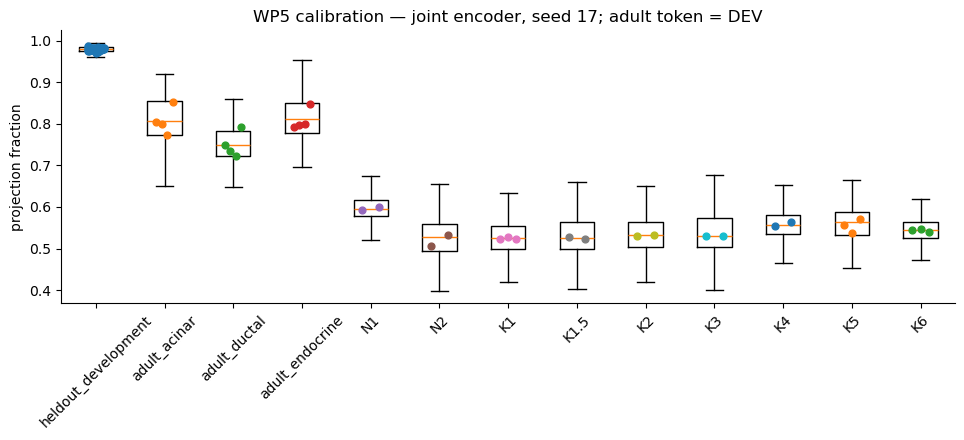

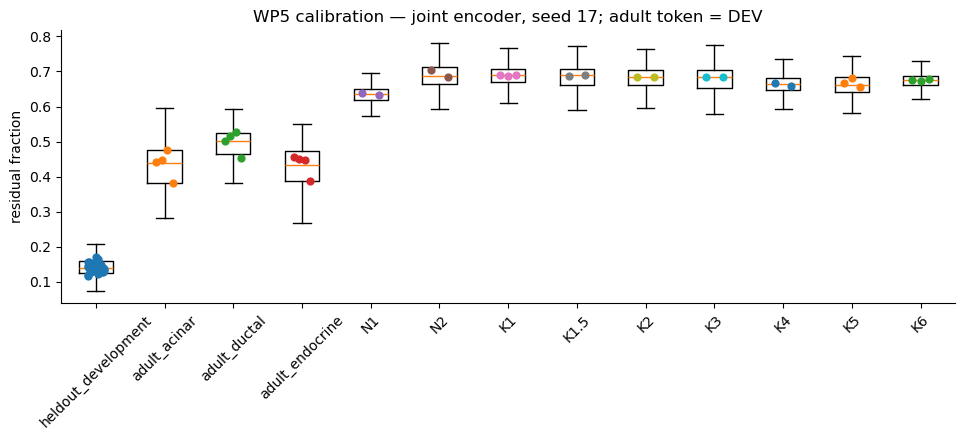

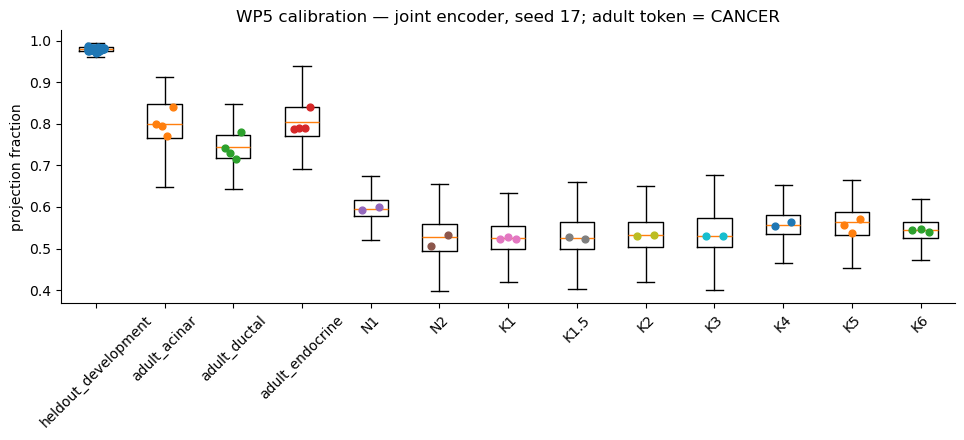

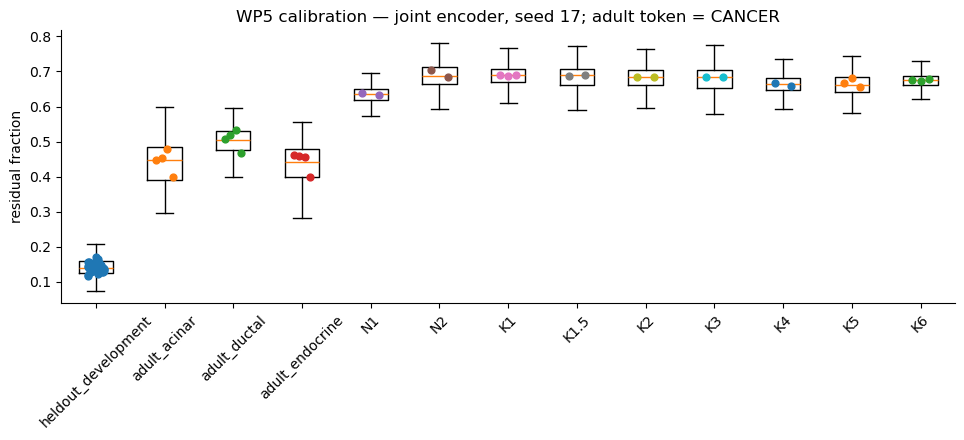

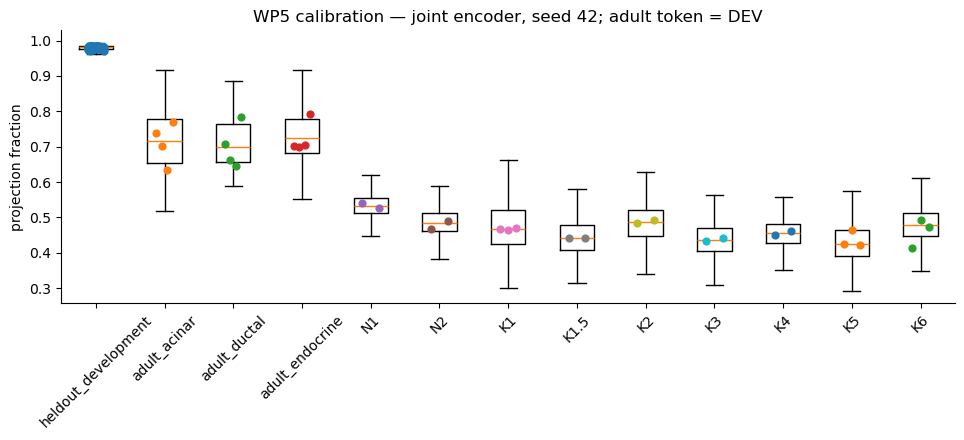

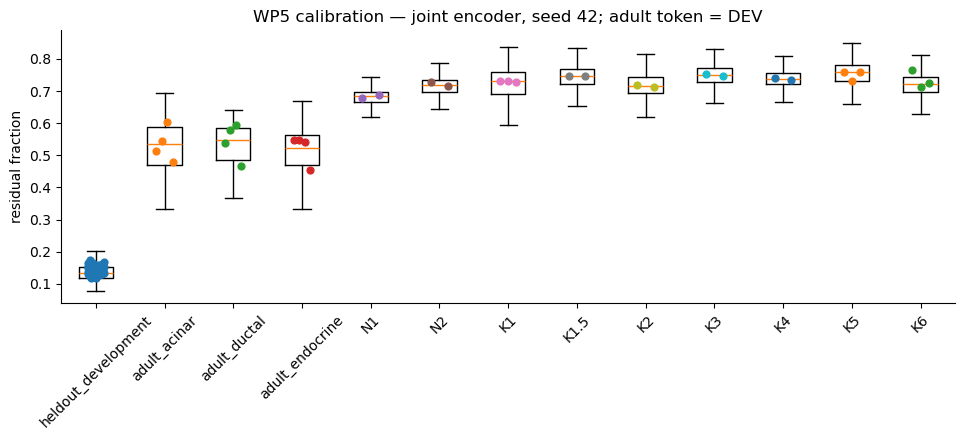

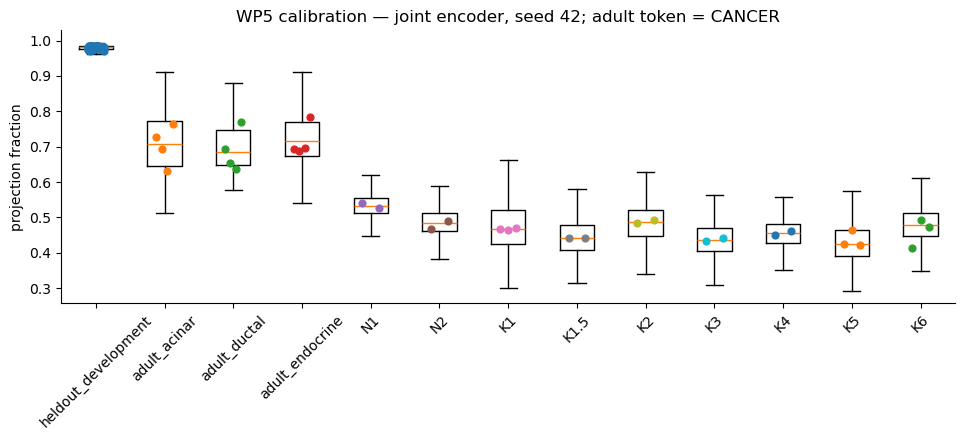

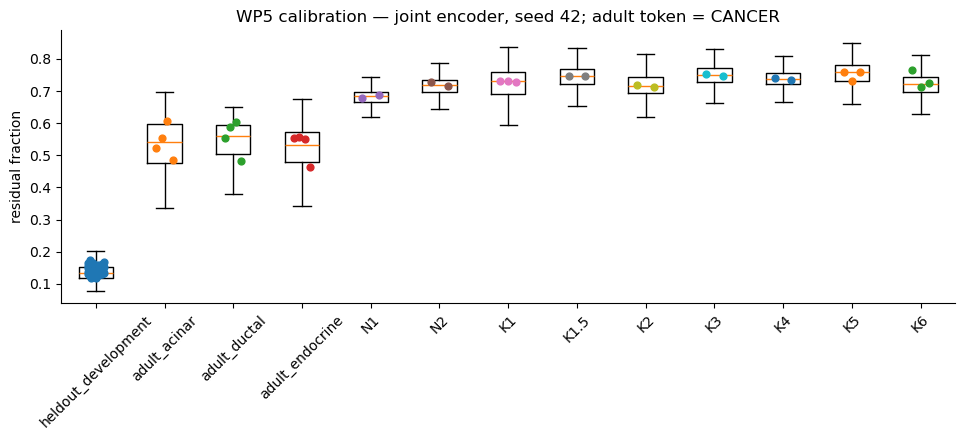

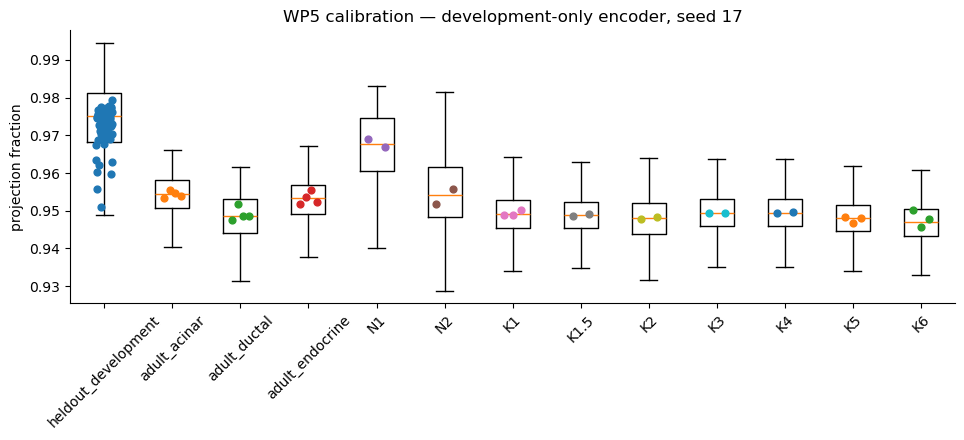

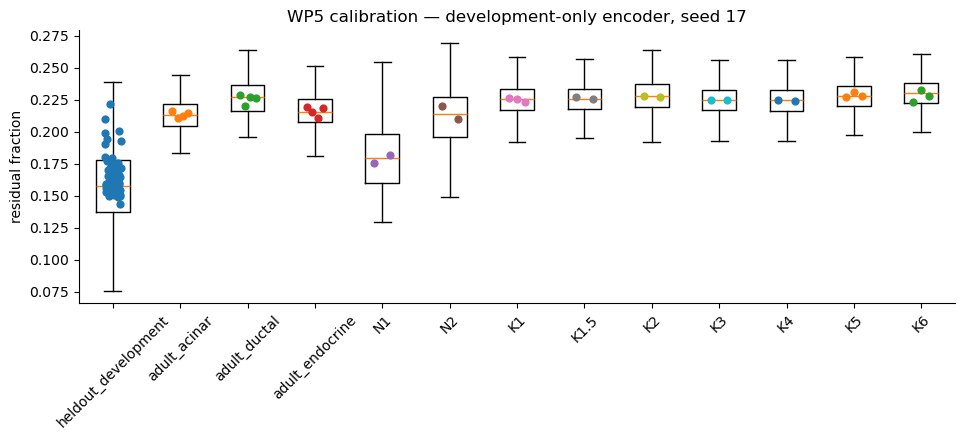

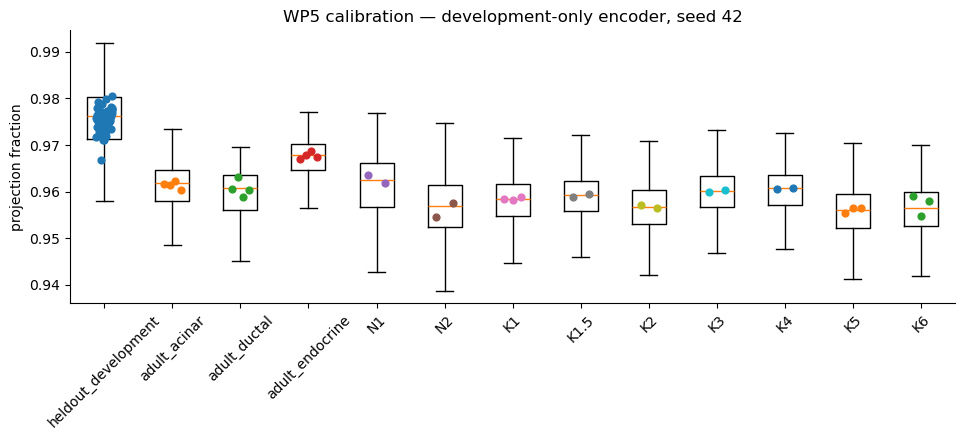

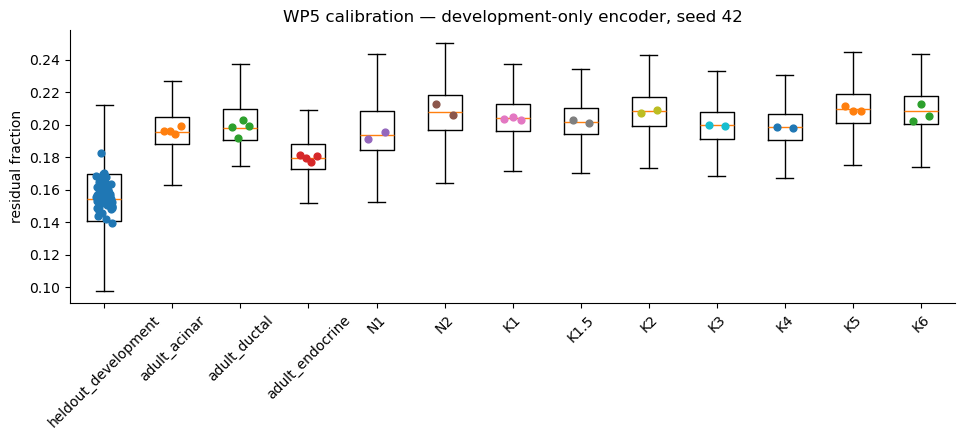

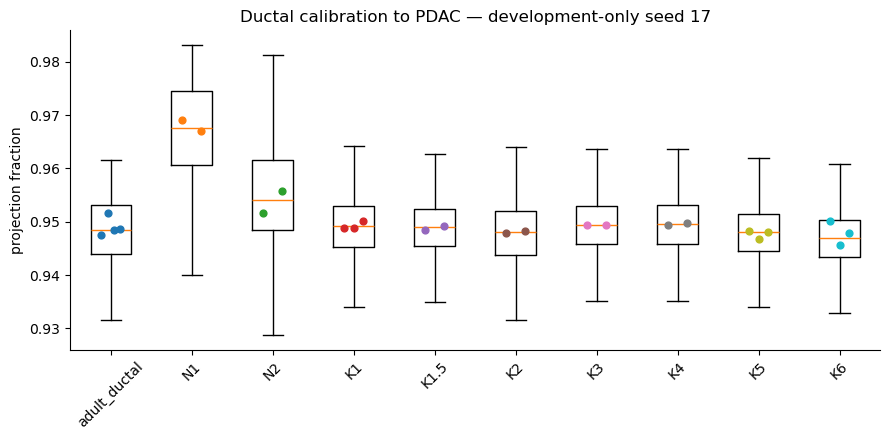

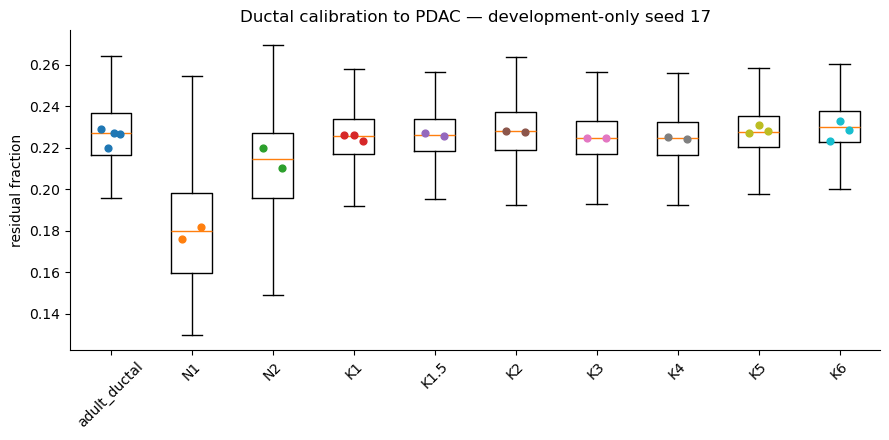

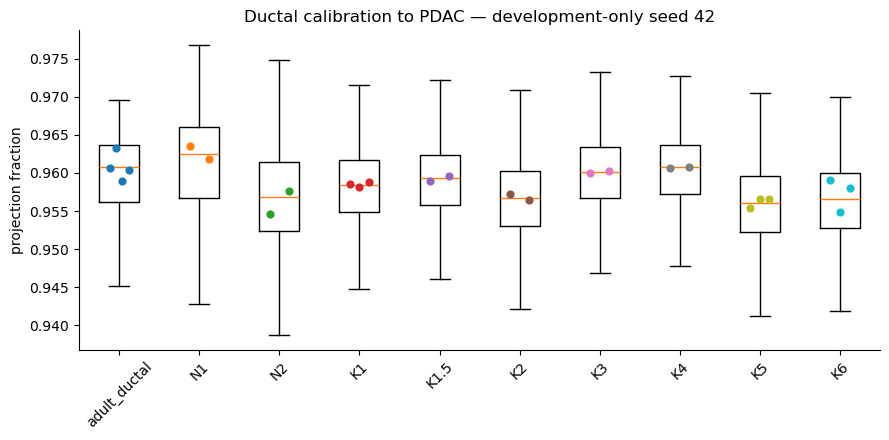

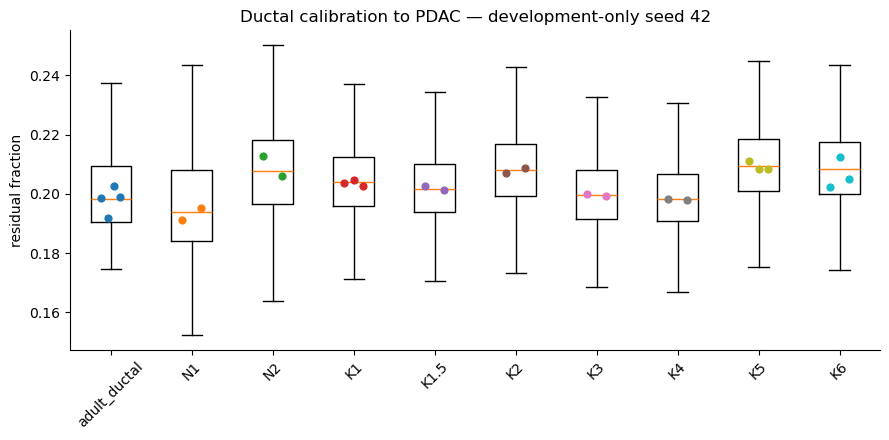

In [ ]:
# Preferred biological order for Burdziak conditions.
ORDER = [
    "heldout_development",
    "adult_acinar", "adult_ductal", "adult_endocrine",
    "N1", "N2", "K1", "K1.5", "K2", "K3", "K4", "K5", "K6",
]


def boxplot_metric(df, metric, title, outfile):
    groups = [g for g in ORDER if g in set(df["group"])]
    data = [df.loc[df["group"] == g, metric].dropna().to_numpy() for g in groups]

    fig, ax = plt.subplots(figsize=(max(9, 0.75*len(groups)), 4.5))
    ax.boxplot(data, tick_labels=groups, showfliers=False)

    # Overlay biological-sample medians where possible.
    ss = (
        df.groupby(["group", "sample_id"])[metric]
        .median()
        .reset_index()
    )
    for i, g in enumerate(groups, start=1):
        vals = ss.loc[ss["group"] == g, metric].to_numpy()
        if len(vals):
            jitter = np.linspace(-0.12, 0.12, len(vals)) if len(vals) > 1 else np.array([0.0])
            ax.scatter(i + jitter, vals, s=24, zorder=3)

    ax.set_ylabel(metric.replace("_", " "))
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=45)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    fig.tight_layout()
    fig.savefig(outfile, dpi=200, bbox_inches="tight")
    plt.show()


# Development-only AE4 seeds are shown separately: do not pool the same cells
# across stochastic model seeds as if they were independent observations.
for enc in ENCODERS:
    sub = metrics[metrics["encoder"] == enc].copy()

    if enc.startswith("development_only_seed"):
        adult_dom = sub.loc[sub["reference_group"] == "adult_normal", "domain_assumption"].iloc[0]
        plot_df = sub[
            (sub["reference_group"] != "adult_normal") |
            (sub["domain_assumption"] == adult_dom)
        ].copy()
        suffix = enc
        seed = encoder_specs[enc].get("seed", "?")
        boxplot_metric(
            plot_df, "projection_fraction",
            f"AE5 calibration — development-only encoder, seed {seed}",
            OUTDIR / f"{suffix}_projection_fraction.png"
        )
        boxplot_metric(
            plot_df, "residual_fraction",
            f"AE5 calibration — development-only encoder, seed {seed}",
            OUTDIR / f"{suffix}_residual_fraction.png"
        )

    elif encoder_specs[enc]["training_scope"] == "joint":
        # For each clean joint seed, show adult DEV/CANCER token assumptions separately.
        nonadult = sub[sub["reference_group"] != "adult_normal"].copy()
        seed = encoder_specs[enc].get("seed", "?")
        for dom in ["DEV", "CANCER"]:
            adult_dom_df = sub[
                (sub["reference_group"] == "adult_normal")
                & (sub["domain_assumption"] == dom)
            ]
            if adult_dom_df.empty:
                continue
            plot_df = pd.concat([nonadult, adult_dom_df], ignore_index=True)
            suffix = f"{enc}_adult_as_{dom}"
            boxplot_metric(
                plot_df, "projection_fraction",
                f"AE5 calibration — joint encoder, seed {seed}; adult token = {dom}",
                OUTDIR / f"{suffix}_projection_fraction.png"
            )
            boxplot_metric(
                plot_df, "residual_fraction",
                f"AE5 calibration — joint encoder, seed {seed}; adult token = {dom}",
                OUTDIR / f"{suffix}_residual_fraction.png"
            )


# -----------------------------
# Focused like-for-like PDAC calibration:
# adult ductal -> N1 -> N2 -> K states
#
# There is intentionally no "held-out developmental ductal" point because
# AE3 established that Qiu lacks a clean pancreatic ductal/trunk endpoint.
# -----------------------------
def ductal_pdac_plot_frame(df):
    parts = []

    # Independent adult ductal only.
    ad = df[
        (df["reference_group"] == "adult_normal") &
        (df["subgroup"] == "ductal")
    ].copy()
    ad["focused_group"] = "adult_ductal"
    parts.append(ad)

    # Burdziak conditions remain separate.
    # N1/N2 are normal/metaplastic references; K1-K6 form the
    # experimental progression series and are displayed individually.
    bc = df[df["reference_group"].isin(["Burdziak_normal", "K_series"])].copy()
    bc["focused_group"] = bc["group"].astype(str)
    parts.append(bc)

    return pd.concat(parts, ignore_index=True, sort=False)


DUCTAL_ORDER = [
    "adult_ductal",
    "N1", "N2", "K1", "K1.5", "K2", "K3", "K4", "K5", "K6"
]


def boxplot_focused_metric(df, metric, title, outfile):
    groups = [g for g in DUCTAL_ORDER if g in set(df["focused_group"])]
    data = [
        df.loc[df["focused_group"] == g, metric].dropna().to_numpy()
        for g in groups
    ]

    fig, ax = plt.subplots(figsize=(max(9, 0.78 * len(groups)), 4.5))
    ax.boxplot(data, tick_labels=groups, showfliers=False)

    ss = (
        df.groupby(["focused_group", "sample_id"])[metric]
        .median()
        .reset_index()
    )
    for i, g in enumerate(groups, start=1):
        vals = ss.loc[ss["focused_group"] == g, metric].to_numpy()
        if len(vals):
            jitter = np.linspace(-0.12, 0.12, len(vals)) if len(vals) > 1 else np.array([0.0])
            ax.scatter(i + jitter, vals, s=24, zorder=3)

    ax.set_ylabel(metric.replace("_", " "))
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=45)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    fig.tight_layout()
    fig.savefig(outfile, dpi=200, bbox_inches="tight")
    plt.show()


for enc in ENCODERS:
    if not enc.startswith("development_only_seed"):
        continue

    seed_df = metrics[metrics["encoder"] == enc].copy()
    focused = ductal_pdac_plot_frame(seed_df)
    seed = encoder_specs[enc].get("seed", "?")

    boxplot_focused_metric(
        focused,
        "projection_fraction",
        f"Ductal calibration to PDAC — development-only seed {seed}",
        OUTDIR / f"{enc}_ductal_pdac_projection_fraction.png",
    )
    boxplot_focused_metric(
        focused,
        "residual_fraction",
        f"Ductal calibration to PDAC — development-only seed {seed}",
        OUTDIR / f"{enc}_ductal_pdac_residual_fraction.png",
    )


/tmp/ipykernel_3246088/239128685.py:15: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


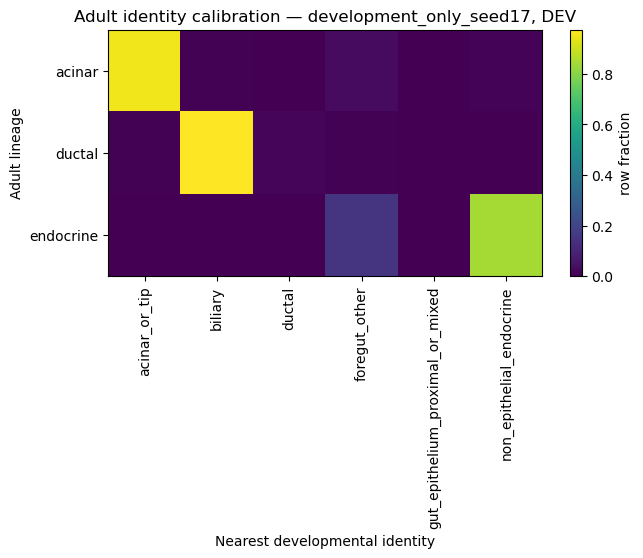

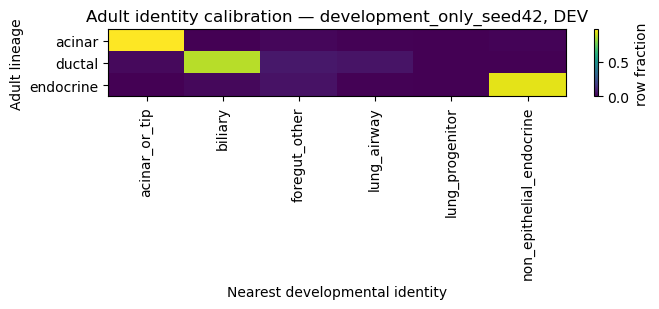

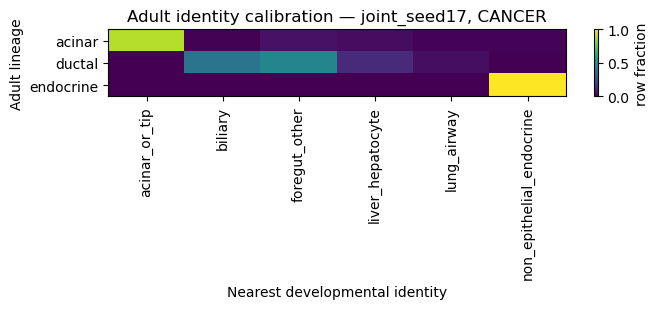

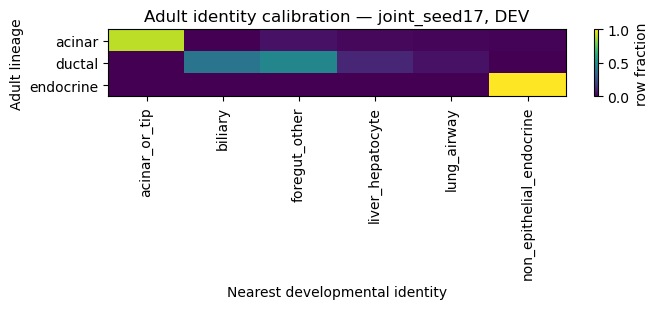

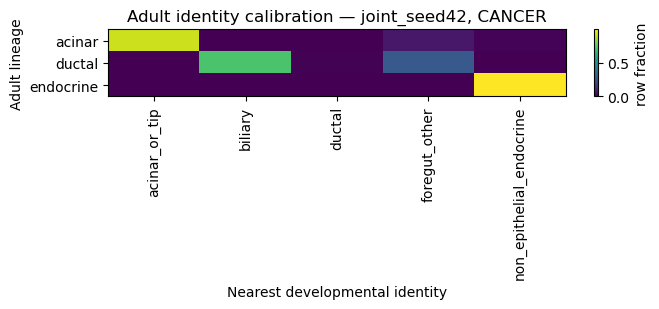

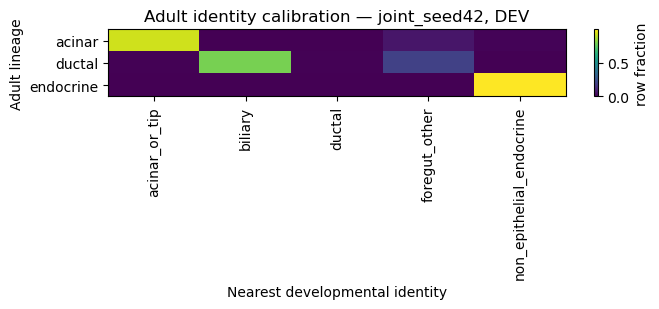

In [29]:
# Adult nearest-developmental-identity heatmaps (simple matplotlib, no forced palette).
for (enc, dom), sub in adult_metrics.groupby(["encoder", "domain_assumption"]):
    tab = pd.crosstab(sub["subgroup"], sub["nearest_dev_identity"], normalize="index")
    if tab.empty:
        continue

    fig, ax = plt.subplots(figsize=(max(7, 0.45*tab.shape[1]), 3.2))
    im = ax.imshow(tab.values, aspect="auto")
    ax.set_yticks(np.arange(tab.shape[0]), labels=tab.index)
    ax.set_xticks(np.arange(tab.shape[1]), labels=tab.columns, rotation=90)
    ax.set_xlabel("Nearest developmental identity")
    ax.set_ylabel("Adult lineage")
    ax.set_title(f"Adult identity calibration — {enc}, {dom}")
    fig.colorbar(im, ax=ax, label="row fraction")
    fig.tight_layout()
    fig.savefig(OUTDIR / f"adult_identity_heatmap_{enc}_{dom}.png", dpi=200, bbox_inches="tight")
    plt.show()


## 10. Final decision diagnostics - audited paired encoders

Interpret AE5 in this hierarchy:

1. **Primary normal calibration:** development-only seeds 17 and 42.
2. **Paired sensitivity:** clean joint seeds 17 and 42 generated by the same audited pipeline.
3. **Overall held-out development:** out-of-sample developmental PCA reconstruction sanity check.
4. **Acinar/endocrine adult identity:** positive lineage calibration.
5. **Adult ductal:** like-for-like normal comparator for Burdziak, but not a prenatal ductal-endpoint identity test.

The key question is no longer whether an old ~40% number can be preserved. 

It is whether normal-versus-malignant ordering and the broader developmental-positioning/directionality distinction are stable across the clean joint and clean development-only model families. 

**AE6** will extend that exact comparison to expression PCA and scVI.


In [ ]:
# -----------------------------
# Primary development-only diagnostics
# -----------------------------
# Bookkeeping guard: adult rows must carry encoder family and seed.
# -----------------------------

adult_devonly_check = metrics[
    (metrics["reference_group"] == "adult_normal")
    & (metrics["encoder"].str.startswith("development_only_seed"))
]

if adult_devonly_check.empty:
    raise RuntimeError("No development-only adult-normal rows found in metrics.")

if adult_devonly_check["encoder_family"].isna().any():
    raise RuntimeError(
        "Adult development-only rows are missing encoder_family; "
        "primary AE5 summaries would silently drop them."
    )

if not adult_devonly_check["encoder_family"].eq("development_only").all():
    raise RuntimeError(
        "Adult development-only rows have incorrect encoder_family."
    )

if adult_devonly_check["model_seed"].isna().any():
    raise RuntimeError(
        "Adult development-only rows are missing model_seed."
    )

print(
    "Adult development-only bookkeeping PASS:",
    adult_devonly_check.groupby(["encoder", "group"]).size().to_dict()
)

# Keep stochastic AE4 seeds separate. Model seeds are robustness checks,
# not biological replicates.

primary_encoders = [
    f"development_only_seed{seed}"
    for seed in DEV_ONLY_SEEDS
]

primary = metrics[
    metrics["encoder"].isin(primary_encoders)
].copy()

print("\nPrimary AE5 groups:")
print(
    primary
    .groupby(["encoder", "reference_group", "group"])
    .size()
    .to_string()
)

rows = []
ductal_rows = []

for enc, enc_df in primary.groupby("encoder"):
    seed = encoder_specs[enc].get("seed", np.nan)

    # Broad, lineage-resolved calibration populations.
    population_masks = {
        "heldout_development_all":
            enc_df["reference_group"].eq("heldout_development"),

        "adult_acinar":
            enc_df["group"].eq("adult_acinar"),

        "adult_ductal":
            enc_df["group"].eq("adult_ductal"),

        "adult_endocrine":
            enc_df["group"].eq("adult_endocrine"),

        "Burdziak_N1":
            enc_df["group"].eq("N1"),

        "Burdziak_N2":
            enc_df["group"].eq("N2"),

        # Entire experimental Kras progression series.
        "K_series_all":
            enc_df["reference_group"].eq("K_series"),

        # Explicit overt malignant/metastatic comparison.
        "overt_malignant_K5_K6":
            enc_df["group"].isin(["K5", "K6"]),
    }

    # Broad calibration summaries.
    for label, mask in population_masks.items():
        sub = enc_df[mask]

        if sub.empty:
            raise RuntimeError(
                f"{enc}: population {label!r} is empty."
            )

        rows.append({
            "encoder": enc,
            "seed": seed,
            "population": label,
            "n_cells": len(sub),
            "n_samples": sub["sample_id"].nunique(),
            "projection_median": sub["projection_fraction"].median(),
            "residual_fraction_median": sub["residual_fraction"].median(),
            "nearest_distance_median": sub["nearest_dev_distance"].median(),
        })

    # Focused adult ductal -> Burdziak progression sequence,
    # preserving each K state.
    focused = ductal_pdac_plot_frame(enc_df)

    for group, sub in focused.groupby(
        "focused_group",
        observed=True,
    ):
        ductal_rows.append({
            "encoder": enc,
            "seed": seed,
            "population": group,
            "n_cells": len(sub),
            "n_samples": sub["sample_id"].nunique(),
            "projection_median": sub["projection_fraction"].median(),
            "projection_q25": sub["projection_fraction"].quantile(.25),
            "projection_q75": sub["projection_fraction"].quantile(.75),
            "residual_fraction_median": sub["residual_fraction"].median(),
            "residual_norm_median": sub["residual_norm"].median(),
            "nearest_distance_median": sub["nearest_dev_distance"].median(),
        })

primary_by_seed = pd.DataFrame(rows)
primary_by_seed.to_csv(OUTDIR / "ae5_primary_diagnostic_by_seed.csv",index=False)
display(primary_by_seed)

ductal_pdac_by_seed = pd.DataFrame(ductal_rows)

ductal_pdac_by_seed["population"] = pd.Categorical(
    ductal_pdac_by_seed["population"],
    categories=DUCTAL_ORDER,
    ordered=True,
)

ductal_pdac_by_seed = ductal_pdac_by_seed.sort_values(["seed", "population"])
ductal_pdac_by_seed.to_csv(
    OUTDIR / "ae5_ductal_pdac_calibration_by_seed.csv",
    index=False,
)

# Adult ductal must be present once for each development-only seed.
adult_ductal_presence = (
    ductal_pdac_by_seed[
        ductal_pdac_by_seed["population"]
        .astype(str)
        .eq("adult_ductal")
    ]
    .groupby("seed")
    .size()
)

expected_seeds = set(DEV_ONLY_SEEDS)

if set(adult_ductal_presence.index.astype(int)) != expected_seeds:
    raise RuntimeError(
        "Focused AE5 table is missing adult_ductal for at least one seed. "
        f"Found: {adult_ductal_presence.to_dict()}"
    )

print(
    "\nFocused adult ductal -> Burdziak progression calibration:"
)
display(ductal_pdac_by_seed)

# Across-seed robustness summary.
# With only two model seeds, report median/range.
diagnostic = (
    primary_by_seed
    .groupby("population")
    .agg(
        n_seeds=("seed", "nunique"),
        projection_median_across_seeds=(
            "projection_median",
            "median",
        ),
        projection_seed_min=(
            "projection_median",
            "min",
        ),
        projection_seed_max=(
            "projection_median",
            "max",
        ),
        residual_fraction_median_across_seeds=(
            "residual_fraction_median",
            "median",
        ),
        residual_seed_min=(
            "residual_fraction_median",
            "min",
        ),
        residual_seed_max=(
            "residual_fraction_median",
            "max",
        ),
        nearest_distance_median_across_seeds=(
            "nearest_distance_median",
            "median",
        ),
    )
    .reset_index()
)

diagnostic.to_csv(
    OUTDIR / "ae5_primary_diagnostic.csv",
    index=False,
)

diagnostic

Adult development-only bookkeeping PASS: {('development_only_seed17', 'adult_acinar'): 182, ('development_only_seed17', 'adult_ductal'): 161, ('development_only_seed17', 'adult_endocrine'): 1052, ('development_only_seed42', 'adult_acinar'): 182, ('development_only_seed42', 'adult_ductal'): 161, ('development_only_seed42', 'adult_endocrine'): 1052}

Primary WP5 groups:
encoder                  reference_group      group              
development_only_seed17  Burdziak_normal      N1                     3225
                                              N2                     2401
                         K_series             K1                     4503
                                              K1.5                   2476
                                              K2                     2079
                                              K3                     3338
                                              K4                     1254
                                             

,encoder,seed,population,n_cells,n_samples,projection_median,residual_fraction_median,nearest_distance_median
0,development_only_seed17,17,heldout_development_all,7082,73,0.975181,0.157541,5.680429
1,development_only_seed17,17,adult_acinar,182,4,0.954432,0.213466,7.868464
2,development_only_seed17,17,adult_ductal,161,4,0.948509,0.226916,7.828702
3,development_only_seed17,17,adult_endocrine,1052,4,0.953476,0.215694,7.655075
4,development_only_seed17,17,Burdziak_N1,3225,2,0.967655,0.179846,8.805514
5,development_only_seed17,17,Burdziak_N2,2401,2,0.954051,0.214356,8.327681
6,development_only_seed17,17,K_series_all,22505,17,0.948482,0.226976,8.489146
7,development_only_seed17,17,overt_malignant_K5_K6,8855,6,0.947680,0.228737,8.499878
8,development_only_seed42,42,heldout_development_all,7082,73,0.976303,0.153939,4.576088
9,development_only_seed42,42,adult_acinar,182,4,0.961769,0.195528,6.755639



Focused adult ductal -> Burdziak progression calibration:


,encoder,seed,population,n_cells,n_samples,projection_median,projection_q25,projection_q75,residual_fraction_median,residual_norm_median,nearest_distance_median
9,development_only_seed17,17,adult_ductal,161,4,0.948509,0.944046,0.953139,0.226916,1.849003,7.828702
7,development_only_seed17,17,N1,3225,2,0.967655,0.960637,0.974485,0.179846,1.704768,8.805514
8,development_only_seed17,17,N2,2401,2,0.954051,0.948417,0.961630,0.214356,1.867468,8.327681
0,development_only_seed17,17,K1,4503,3,0.949166,0.945354,0.952910,0.225465,1.953755,8.462733
1,development_only_seed17,17,K1.5,2476,2,0.948942,0.945370,0.952363,0.225959,1.968564,8.483620
2,development_only_seed17,17,K2,2079,2,0.948052,0.943751,0.951985,0.227923,1.957019,8.438266
3,development_only_seed17,17,K3,3338,2,0.949446,0.945821,0.952981,0.224841,1.958782,8.518076
4,development_only_seed17,17,K4,1254,2,0.949503,0.945885,0.953080,0.224716,1.955628,8.524763
5,development_only_seed17,17,K5,5364,3,0.948134,0.944541,0.951526,0.227741,1.966855,8.507156
6,development_only_seed17,17,K6,3491,3,0.947050,0.943419,0.950417,0.230109,1.996806,8.490909


,population,n_seeds,projection_median_across_seeds,projection_seed_min,projection_seed_max,residual_fraction_median_across_seeds,residual_seed_min,residual_seed_max,nearest_distance_median_across_seeds
0,Burdziak_N1,2,0.965064,0.962473,0.967655,0.186782,0.179846,0.193719,8.121917
1,Burdziak_N2,2,0.955461,0.954051,0.956870,0.211017,0.207678,0.214356,7.827532
2,K_series_all,2,0.953202,0.948482,0.957921,0.216053,0.205131,0.226976,7.927677
3,adult_acinar,2,0.958100,0.954432,0.961769,0.204497,0.195528,0.213466,7.312052
4,adult_ductal,2,0.954623,0.948509,0.960737,0.212532,0.198148,0.226916,7.331702
5,adult_endocrine,2,0.960645,0.953476,0.967814,0.197549,0.179404,0.215694,7.308159
6,heldout_development_all,2,0.975742,0.975181,0.976303,0.155740,0.153939,0.157541,5.128258
7,overt_malignant_K5_K6,2,0.951965,0.947680,0.956251,0.218950,0.209162,0.228737,7.919224


In [ ]:
# -----------------------------
# Like-for-like adult DUCTAL vs Burdziak diagnostics
# -----------------------------
# Do not use a pooled adult-normal value here: endocrine cells numerically
# dominate the adult epithelial benchmark.
#
# There is deliberately no "held-out developmental ductal" comparator because
# the finalized AE3 reference does not contain a clean pancreatic ductal/trunk endpoint.
#
# K1-K6 are retained as the full experimental progression series.
# K5-K6 provide the explicit overt malignant/metastatic comparator.

gap_rows = []

for enc, enc_df in primary.groupby("encoder"):
    seed = encoder_specs[enc].get("seed", np.nan)

    adult_ductal = enc_df[enc_df["group"] == "adult_ductal"]
    n1 = enc_df[enc_df["group"] == "N1"]
    n2 = enc_df[enc_df["group"] == "N2"]

    k_series = enc_df[enc_df["reference_group"] == "K_series"]
    overt_malignant = enc_df[enc_df["group"].isin(["K5", "K6"])]

    if adult_ductal.empty:
        raise RuntimeError(
            f"{enc}: no adult ductal cells found."
        )

    if n1.empty or n2.empty:
        raise RuntimeError(
            f"{enc}: N1 and/or N2 cells are missing."
        )

    if k_series.empty:
        raise RuntimeError(
            f"{enc}: no K-series cells found."
        )

    if overt_malignant.empty:
        raise RuntimeError(
            f"{enc}: no K5/K6 overt malignant cells found."
        )

    row = {
        "encoder": enc,
        "seed": seed,

        "adult_ductal_projection_median":
            adult_ductal["projection_fraction"].median(),

        "N1_projection_median":
            n1["projection_fraction"].median(),

        "N2_projection_median":
            n2["projection_fraction"].median(),

        "K_series_projection_median":
            k_series["projection_fraction"].median(),

        "overt_malignant_K5_K6_projection_median":
            overt_malignant["projection_fraction"].median(),

        "adult_ductal_residual_fraction_median":
            adult_ductal["residual_fraction"].median(),

        "K_series_residual_fraction_median":
            k_series["residual_fraction"].median(),

        "overt_malignant_K5_K6_residual_fraction_median":
            overt_malignant["residual_fraction"].median(),

        "adult_ductal_minus_K_series_projection": (
            adult_ductal["projection_fraction"].median()
            - k_series["projection_fraction"].median()
        ),

        "adult_ductal_minus_overt_malignant_K5_K6_projection": (
            adult_ductal["projection_fraction"].median()
            - overt_malignant["projection_fraction"].median()
        ),

        "K_series_minus_adult_ductal_residual_fraction": (
            k_series["residual_fraction"].median()
            - adult_ductal["residual_fraction"].median()
        ),

        "overt_malignant_K5_K6_minus_adult_ductal_residual_fraction": (
            overt_malignant["residual_fraction"].median()
            - adult_ductal["residual_fraction"].median()
        ),

        "adult_ductal_minus_N1_projection": (
            adult_ductal["projection_fraction"].median()
            - n1["projection_fraction"].median()
        ),

        "adult_ductal_minus_N2_projection": (
            adult_ductal["projection_fraction"].median()
            - n2["projection_fraction"].median()
        ),
    }

    gap_rows.append(row)

    print(f"Development-only seed {seed}")
    print(
        "  adult ductal projection:        ",
        row["adult_ductal_projection_median"]
    )
    print(
        "  N1 projection:                  ",
        row["N1_projection_median"]
    )
    print(
        "  N2 projection:                  ",
        row["N2_projection_median"]
    )
    print(
        "  all K-series projection:        ",
        row["K_series_projection_median"]
    )
    print(
        "  overt malignant K5-K6 projection:",
        row["overt_malignant_K5_K6_projection_median"]
    )
    print(
        "  adult ductal - K5/K6 projection:",
        row[
            "adult_ductal_minus_overt_malignant_K5_K6_projection"
        ]
    )

    if (
        np.isfinite(row["adult_ductal_projection_median"])
        and np.isfinite(
            row["overt_malignant_K5_K6_projection_median"]
        )
        and row["adult_ductal_projection_median"]
        <= row["overt_malignant_K5_K6_projection_median"] + 0.05
    ):
        print(
            "  [DECISION FLAG] Adult ductal projection is close "
            "to overt malignant K5/K6 projection."
        )
        print(
            "  Do NOT describe low absolute projection as "
            "intrinsically malignant."
        )
        print(
            "  Proceed to AE6 representation robustness."
        )


gaps_by_seed = pd.DataFrame(gap_rows)

critical_gap_cols = [
    "adult_ductal_projection_median",
    "adult_ductal_residual_fraction_median",
    "K_series_projection_median",
    "overt_malignant_K5_K6_projection_median",
    "adult_ductal_minus_K_series_projection",
    "adult_ductal_minus_overt_malignant_K5_K6_projection",
    "K_series_minus_adult_ductal_residual_fraction",
    "overt_malignant_K5_K6_minus_adult_ductal_residual_fraction",
    "adult_ductal_minus_N1_projection",
    "adult_ductal_minus_N2_projection",
]

if gaps_by_seed[critical_gap_cols].isna().any().any():
    raise RuntimeError(
        "NaN detected in adult-ductal gap diagnostics. "
        "Check that adult-normal, K-series, and K5/K6 rows "
        "are retained in the development-only primary table."
    )

gaps_by_seed.to_csv(
    OUTDIR / "ae5_adult_ductal_vs_pdac_gaps_by_seed.csv",
    index=False,
)

gaps_by_seed

Development-only seed 17
  adult ductal projection:         0.948509
  N1 projection:                   0.96765536
  N2 projection:                   0.95405143
  all K-series projection:         0.94848216
  overt malignant K5-K6 projection: 0.9476796
  adult ductal - K5/K6 projection: 0.00082939863
  [DECISION FLAG] Adult ductal projection is close to overt malignant K5/K6 projection.
  Do NOT describe low absolute projection as intrinsically malignant.
  Proceed to WP6 representation robustness.
Development-only seed 42
  adult ductal projection:         0.9607368
  N1 projection:                   0.96247286
  N2 projection:                   0.9568697
  all K-series projection:         0.9579211
  overt malignant K5-K6 projection: 0.956251
  adult ductal - K5/K6 projection: 0.004485786
  [DECISION FLAG] Adult ductal projection is close to overt malignant K5/K6 projection.
  Do NOT describe low absolute projection as intrinsically malignant.
  Proceed to WP6 representation robustne

,encoder,seed,adult_ductal_projection_median,N1_projection_median,N2_projection_median,K_series_projection_median,overt_malignant_K5_K6_projection_median,adult_ductal_residual_fraction_median,K_series_residual_fraction_median,overt_malignant_K5_K6_residual_fraction_median,adult_ductal_minus_K_series_projection,adult_ductal_minus_overt_malignant_K5_K6_projection,K_series_minus_adult_ductal_residual_fraction,overt_malignant_K5_K6_minus_adult_ductal_residual_fraction,adult_ductal_minus_N1_projection,adult_ductal_minus_N2_projection
0,development_only_seed17,17,0.948509,0.967655,0.954051,0.948482,0.947680,0.226916,0.226976,0.228737,0.000027,0.000829,0.000059,0.001820,-0.019146,-0.005542
1,development_only_seed42,42,0.960737,0.962473,0.956870,0.957921,0.956251,0.198148,0.205131,0.209162,0.002816,0.004486,0.006983,0.011014,-0.001736,0.003867


## 11. What goes into the revised paper - final audited AE5 package

### Independent adult-normal calibration
Keep adult lineages separate:

- **Acinar:** lineage sanity check against Qiu tip/acinar states.
- **Endocrine:** lineage sanity check against Qiu endocrine/islet states.
- **Ductal:** normal adult comparator for PDAC projection/residual magnitude; do not claim Qiu contains a validated prenatal pancreatic ductal endpoint.

### PDAC-focused sequence
Use:

**independent adult ductal → Burdziak N1 → Burdziak N2 → K-series progression, with K5–K6 as the overt malignant/metastatic comparator**

alongside the overall held-out-development reconstruction control.

### Representation comparison
Show clean joint and clean development-only encoders separately and preserve model seeds as stochastic robustness checks rather than biological replicates.

Absolute projection fractions are representation-dependent quantities. The manuscript should emphasize comparisons that remain coherent across representation families, not one privileged percentage.

### AE5 status: CLOSED after rerun against the AE1b manifest



In [ ]:
print("AE5 outputs written to:", OUTDIR)
print("\nKey validation/calibration outputs:")
key_outputs = [
    "ae5_tabula_muris_mouse_by_lineage.csv",
    "ae5_tabula_muris_endocrine_by_mouse.csv",
    "ae5_tabula_muris_pancreas_celltype_counts.csv",
    "ae5_adult_identity_summary.csv",
    "ae5_adult_nearest_identity_long.csv",
    "ae5_ductal_pdac_calibration_by_seed.csv",
    "ae5_adult_ductal_vs_pdac_gaps_by_seed.csv",
]
for name in key_outputs:
    p = OUTDIR / name
    print(("OK   " if p.exists() else "PEND "), name)

print("\nAll AE5 files currently present:")
for p in sorted(OUTDIR.glob("ae5_*")):
    print(" -", p.name)


WP5 outputs written to: /home/jfpoyatos/Work/MNCN_24_25/Development_and_PDAC/data/revision_audited_mlm/analysis/wp5_adult_normal_calibration

Key validation/calibration outputs:
OK    wp5_tabula_muris_mouse_by_lineage.csv
OK    wp5_tabula_muris_endocrine_by_mouse.csv
OK    wp5_tabula_muris_pancreas_celltype_counts.csv
OK    wp5_adult_identity_summary.csv
OK    wp5_adult_nearest_identity_long.csv
OK    wp5_ductal_pdac_calibration_by_seed.csv
OK    wp5_adult_ductal_vs_pdac_gaps_by_seed.csv

All WP5 files currently present:
 - wp5_adult_cls_for_wp7.npz
 - wp5_adult_ductal_vs_pdac_gaps_by_seed.csv
 - wp5_adult_identity_summary.csv
 - wp5_adult_nearest_identity_long.csv
 - wp5_adult_obs_for_wp7.csv
 - wp5_audited_token_validation.csv
 - wp5_cell_metrics.csv.gz
 - wp5_ductal_pdac_calibration_by_seed.csv
 - wp5_group_summary.csv
 - wp5_hierarchical_bootstrap.csv
 - wp5_joint_domain_token_sensitivity_by_seed.csv
 - wp5_primary_diagnostic.csv
 - wp5_primary_diagnostic_by_seed.csv
 - wp5_sample_